<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab8_2_PCA_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Componentes Principales (PCA)
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [documentación de PCA en scikit-learn](https://scikit-learn.org/stable/modules/decomposition.html#pca)

---

### Objetivos de aprendizaje

1. Explicar qué hace PCA y por qué es útil para datos ambientales de alta dimensión.
2. Describir los pasos de PCA: centrar, matriz de covarianza, eigenvectores y eigenvalores.
3. Interpretar eigenvalores, varianza explicada y gráficas de Scree.
4. Usar PCA para visualizar datos de alta dimensión en 2D.
5. Aplicar PCA como paso de preprocesamiento antes de clasificación.
6. Combinar PCA con K-Means para visualizar e interpretar grupos.
7. Construir un biplot e interpretar los vectores de carga.
8. Aplicar PCA a atributos reales de **136 cuencas peruanas (CAMELS-PE)** para una regionalización hidrológica.

## Un ejemplo para empezar: comprar un auto

Antes de ver el algoritmo, pensemos en un problema cotidiano.

Imagina que buscas un auto usado. Abres una página web y te abruma la información: marca, modelo, año, kilometraje,
cilindrada, potencia, tipo de combustible, transmisión, número de dueños, historial de choques, estado de las llantas,
color, número de asientos, maletera, sistema de sonido, calificación de seguridad...

Fácilmente son **más de 20 características** por auto. Comparar cientos de avisos con 20 columnas cada uno es paralizante:
tu cerebro no puede comparar todas esas dimensiones a la vez.

¿Qué haces en la práctica? **Filtras** mentalmente: "Para lo que necesito, lo que *realmente* importa es el precio,
el kilometraje, el año y el consumo de combustible. Lo demás es ruido; por ahora ignoro la maletera y el sistema de sonido".

**Acabas de hacer PCA en tu cabeza.** Tomaste un conjunto de datos de alta dimensión (20+ características), identificaste
las direcciones de variación que más importan y comprimiste tu decisión a 3–4 dimensiones clave. PCA hace exactamente eso,
pero de forma matemática y automática.

### La analogía del resumen de un libro

Leer un libro de 1000 páginas es un lujo que pocos pueden darse. ¿No sería ideal resumir lo más importante en 2–3 páginas?
Se pierden detalles, pero se obtiene el panorama general, que suele ser lo que se necesita para tomar decisiones.

PCA es ese "resumidor" de datos: lee el libro completo (todas las variables), identifica las principales "líneas argumentales"
(las direcciones de máxima varianza) y entrega un resumen de pocas páginas (unos pocos componentes principales) que cuenta casi toda la historia.

En datos ambientales peruanos, el "libro" puede ser una estación con decenas de variables meteorológicas, un pixel con 6 bandas
espectrales o una cuenca descrita con 50 atributos.

## 1. Motivación: Demasiadas Dimensiones

Los datasets ambientales peruanos son frecuentemente de **alta dimensión**:

- Un pixel Landsat 8 tiene **6 bandas espectrales** (Azul, Verde, Rojo, NIR, SWIR1, SWIR2)
- Un levantamiento de parcelas de vegetación en la puna puede registrar **50+ especies**
- Un dataset de una torre de flujos puede tener **20+ variables** meteorológicas y de flujos
- Los datos de índices climáticos del SENAMHI abarcan decenas de estaciones y variables
- El dataset **CAMELS-PE** describe cada cuenca con **más de 50 atributos** de clima, relieve, suelos, geología y cobertura

Esto crea varios problemas:
- No puedes **visualizar** más de 2–3 dimensiones a la vez
- Muchas características están **correlacionadas** (ej. temperatura y altura están correlacionadas en los Andes)
- KNN y K-Means sufren la **maldición de la dimensionalidad**

**PCA resuelve esto** encontrando un nuevo conjunto de ejes —llamados **componentes principales**— que capturan la máxima varianza en el menor número de dimensiones.

Es una forma de **comprimir** los datos sin perder mucha información.

## 2. La idea clave: varianza = información

Antes de ver la mecánica de PCA, necesitamos entender una idea fundamental: **la varianza es información**.
Cuanto más varía una característica en tu conjunto de datos, más útil es para distinguir entre observaciones.
Cuanto menos varía, menos te dice.

### El juego de adivinar

Te muestran tres estaciones del SENAMHI con el nombre tapado y debes identificarlas **solo por su altitud**:

| Estación | Altitud (msnm) |
|---|---|
| Callao | 10 |
| Huancayo | 3 313 |
| Puno | 3 820 |

¡Fácil! Las altitudes varían mucho (alta varianza): la de la costa es inconfundible y las dos andinas se distinguen bien.

Ahora intenta con otras tres estaciones del altiplano: Puno (3 820 m), Juliaca (3 826 m) e Ilave (3 850 m).
Sus altitudes son casi idénticas (baja varianza) y **no puedes distinguirlas**. Para este grupo, la altitud casi no aporta información.

*(Altitudes aproximadas, con fines ilustrativos).*

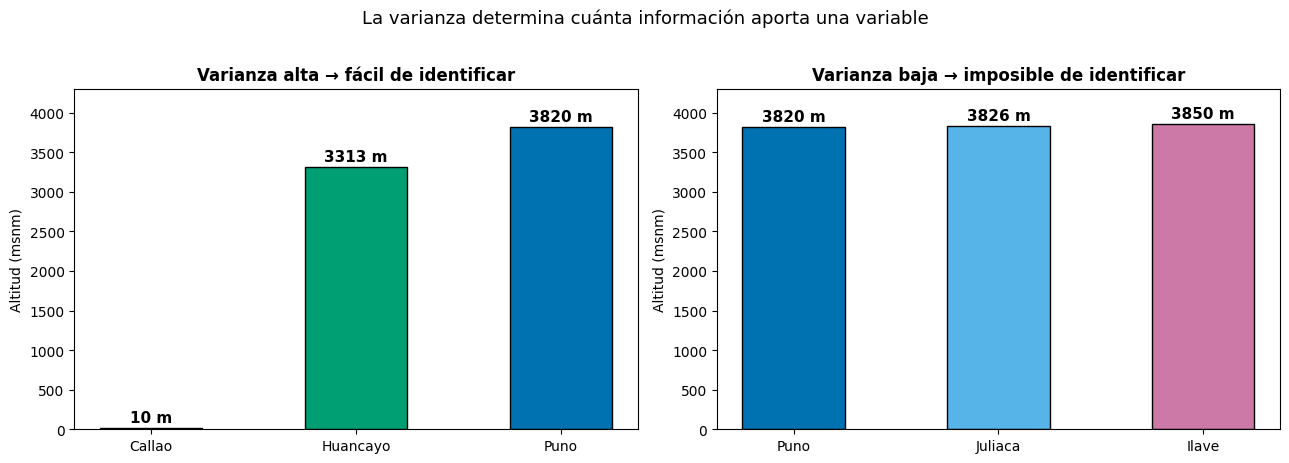

Desviación estándar grupo 1:  1689.3 m
Desviación estándar grupo 2:    13.0 m


In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

# ── Varianza alta: fácil de distinguir ──
est_av = ['Callao', 'Huancayo', 'Puno']
alt_av = [10, 3313, 3820]
ejes[0].bar(est_av, alt_av, color=['#E69F00', '#009E73', '#0072B2'], width=0.5, edgecolor='k')
ejes[0].set_title('Varianza alta → fácil de identificar', fontweight='bold')
for i, h in enumerate(alt_av):
    ejes[0].text(i, h + 80, f'{h} m', ha='center', fontsize=11, fontweight='bold')

# ── Varianza baja: imposible de distinguir ──
est_bv = ['Puno', 'Juliaca', 'Ilave']
alt_bv = [3820, 3826, 3850]
ejes[1].bar(est_bv, alt_bv, color=['#0072B2', '#56B4E9', '#CC79A7'], width=0.5, edgecolor='k')
ejes[1].set_title('Varianza baja → imposible de identificar', fontweight='bold')
for i, h in enumerate(alt_bv):
    ejes[1].text(i, h + 80, f'{h} m', ha='center', fontsize=11, fontweight='bold')

for ax in ejes:
    ax.set_ylabel('Altitud (msnm)')
    ax.set_ylim(0, 4300)

plt.suptitle('La varianza determina cuánta información aporta una variable', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Desviación estándar grupo 1: {np.std(alt_av):7.1f} m")
print(f"Desviación estándar grupo 2: {np.std(alt_bv):7.1f} m")

**Este es el principio que guía a PCA:** las variables con varianza alta llevan información útil; las de varianza baja son
mayormente ruido. PCA busca las direcciones de los datos con **varianza máxima**: esas son los componentes principales.

### Con datos climáticos de cuencas
Supongamos que tienes dos variables climatológicas medidas en 5 cuencas peruanas:

| Cuenca | Precipitación anual (mm) | Temperatura media (°C) |
|--------|------------------------|------------------------|
| Cuenca A (Amazónica alta) | 3500 | 20 |
| Cuenca B (Amazónica media) | 2500 | 24 |
| Cuenca C (Andina) | 900 | 15 |
| Cuenca D (Costera húmeda) | 500 | 22 |
| Cuenca E (Costera árida) | 20 | 19 |

La precipitación varía enormemente → alta varianza → distingue bien las cuencas.
Si solo tuvieras temperatura, sería mucho más difícil diferenciarlas.

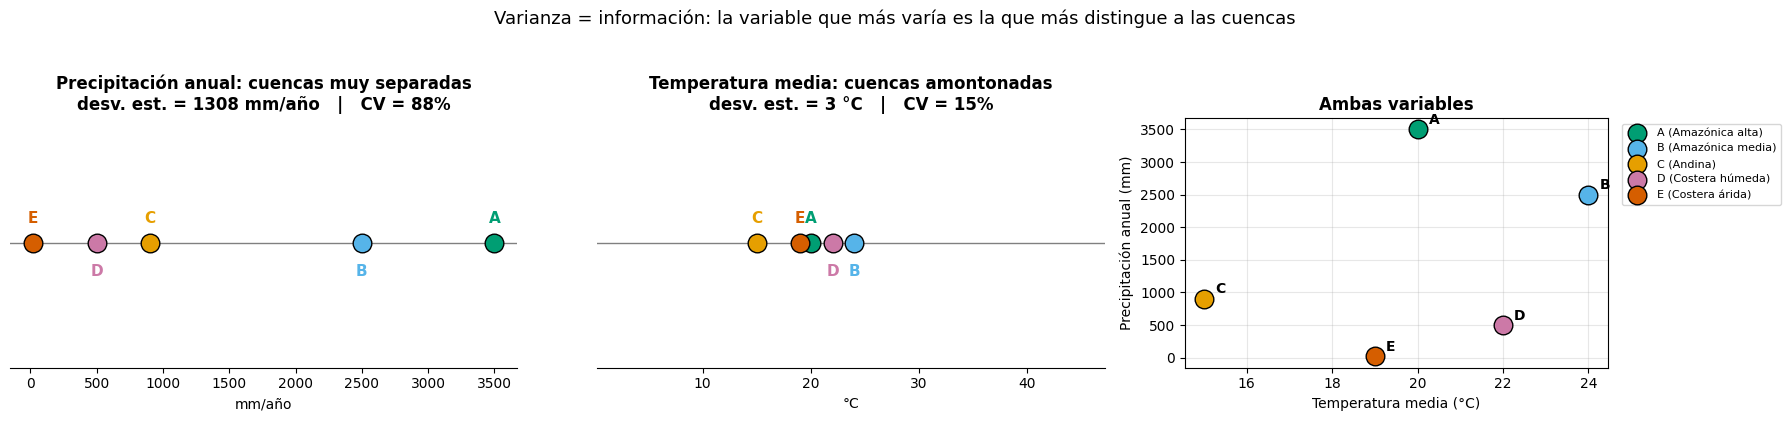

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Las 5 cuencas de la tabla
cuencas = ['A\n(Amazónica alta)', 'B\n(Amazónica media)', 'C\n(Andina)', 'D\n(Costera húmeda)', 'E\n(Costera árida)']
precip_tabla = np.array([3500, 2500, 900, 500, 20])   # mm/año
temp_tabla   = np.array([20, 24, 15, 22, 19])         # °C
colores_cuenca = ['#009E73', '#56B4E9', '#E69F00', '#CC79A7', '#D55E00']

def dispersion_1d(ax, valores, unidad, titulo):
    """Ubica las cuencas sobre un solo eje: cuanto más separadas, más fácil distinguirlas."""
    ax.axhline(0, color='gray', lw=1, zorder=0)
    for k, (v, nombre, color) in enumerate(zip(valores, cuencas, colores_cuenca)):
        ax.scatter(v, 0, s=180, color=color, edgecolors='k', zorder=3)
        ax.annotate(nombre.split(chr(10))[0], (v, 0), xytext=(0, 14 if k % 2 == 0 else -24),
                    textcoords='offset points', ha='center', fontsize=11, color=color, fontweight='bold')
    cv = valores.std() / valores.mean()
    ax.set_title(f'{titulo}\ndesv. est. = {valores.std():.0f} {unidad}   |   CV = {cv:.0%}', fontweight='bold')
    ax.set_xlabel(unidad)
    ax.set_yticks([]); ax.set_ylim(-0.4, 0.4)
    for lado in ['left', 'right', 'top']:
        ax.spines[lado].set_visible(False)

fig, ejes = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={'width_ratios': [1.2, 1.2, 1]})
dispersion_1d(ejes[0], precip_tabla, 'mm/año', 'Precipitación anual: cuencas muy separadas')
dispersion_1d(ejes[1], temp_tabla, '°C', 'Temperatura media: cuencas amontonadas')
ejes[1].set_xlim(precip_tabla.min() / precip_tabla.mean() * temp_tabla.mean(),
                 precip_tabla.max() / precip_tabla.mean() * temp_tabla.mean())   # misma escala relativa que el panel 1

# Las dos variables juntas
for x, y, nombre, color in zip(temp_tabla, precip_tabla, cuencas, colores_cuenca):
    ejes[2].scatter(x, y, s=180, color=color, edgecolors='k', zorder=3, label=nombre.replace(chr(10), ' '))
    ejes[2].annotate(nombre.split('\n')[0], (x, y), xytext=(8, 4), textcoords='offset points', fontweight='bold')
ejes[2].set_xlabel('Temperatura media (°C)'); ejes[2].set_ylabel('Precipitación anual (mm)')
ejes[2].set_title('Ambas variables', fontweight='bold'); ejes[2].grid(alpha=0.3)
ejes[2].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))

plt.suptitle('Varianza = información: la variable que más varía es la que más distingue a las cuencas', fontsize=13, y=1.04)
plt.tight_layout()
plt.show()

Los paneles 1 y 2 usan la **misma escala relativa** (el eje va de mín/media a máx/media), así que se puede comparar
cuánto "se abren" las cuencas en cada variable:

- En **precipitación** las cinco cuencas quedan bien separadas: conocer solo esta variable basta para casi identificarlas.
- En **temperatura** quedan amontonadas entre 15 y 24 °C: por sí sola dice poco.

> **Ojo con las unidades:** la desviación estándar de la precipitación (mm) y la de la temperatura (°C) no son comparables
> directamente. Por eso usamos el **coeficiente de variación** (CV = desv. est. / media) y, en PCA, **estandarizamos** las variables
> antes de buscar las direcciones de máxima varianza.

### ¿Y si dos variables tienen la misma varianza?

Supongamos ahora que conocemos **dos** variables por estación, por ejemplo la temperatura media y la evapotranspiración potencial (ETP),
y que ambas varían de forma parecida entre estaciones. Usarías las dos. Pero, ¿podrías quedarte con una y descartar la otra?
No sin riesgo: perderías parte de la información.

Aquí PCA es más astuto. En lugar de **elegir** una variable y descartar la otra, PCA las **combina**: crea un eje nuevo,
una mezcla ponderada de temperatura y ETP, que captura **más varianza que cualquiera de las dos por separado**.
Ese eje nuevo es el primer componente principal. Lo vemos en la siguiente sección.

## 3. La intuición: encontrar el mejor ángulo de visión

### La analogía de la sombra

Imagina que sostienes una escultura 3D de un cóndor y la apuntas con una linterna para proyectar
una sombra 2D en la pared. Dependiendo del ángulo, la sombra podría verse como un manchón (mal ángulo)
o una silueta reconocible (buen ángulo: se preservó la mayor información).

**PCA encuentra el ángulo que produce la sombra más informativa.** Proyecta datos de alta dimensión en
dimensiones inferiores preservando la mayor variabilidad.

### Un ejemplo en 2D

Imagina una nube de puntos en 2D con forma de **elipse alargada**. Podríamos proyectarla sobre infinitos ejes, pero:

- **CP1** (primer componente principal) es el eje a lo largo de la dirección **más larga** de la elipse: captura la mayor varianza.
- **CP2** es **perpendicular** a CP1 y captura la varianza restante.

Si la elipse es muy alargada, CP1 solo captura casi toda la información y podemos ignorar CP2: comprimimos de 2D a 1D con una pérdida mínima.

### Ejemplo: un gradiente altitudinal andino

A lo largo de un transecto costa–Andes, la **temperatura** y la **evapotranspiración potencial (ETP)** disminuyen
ambas con la altitud, así que están fuertemente correlacionadas. Dos variables que "dicen casi lo mismo"
son el caso ideal para PCA: un solo eje (CP1) resume casi toda la información.

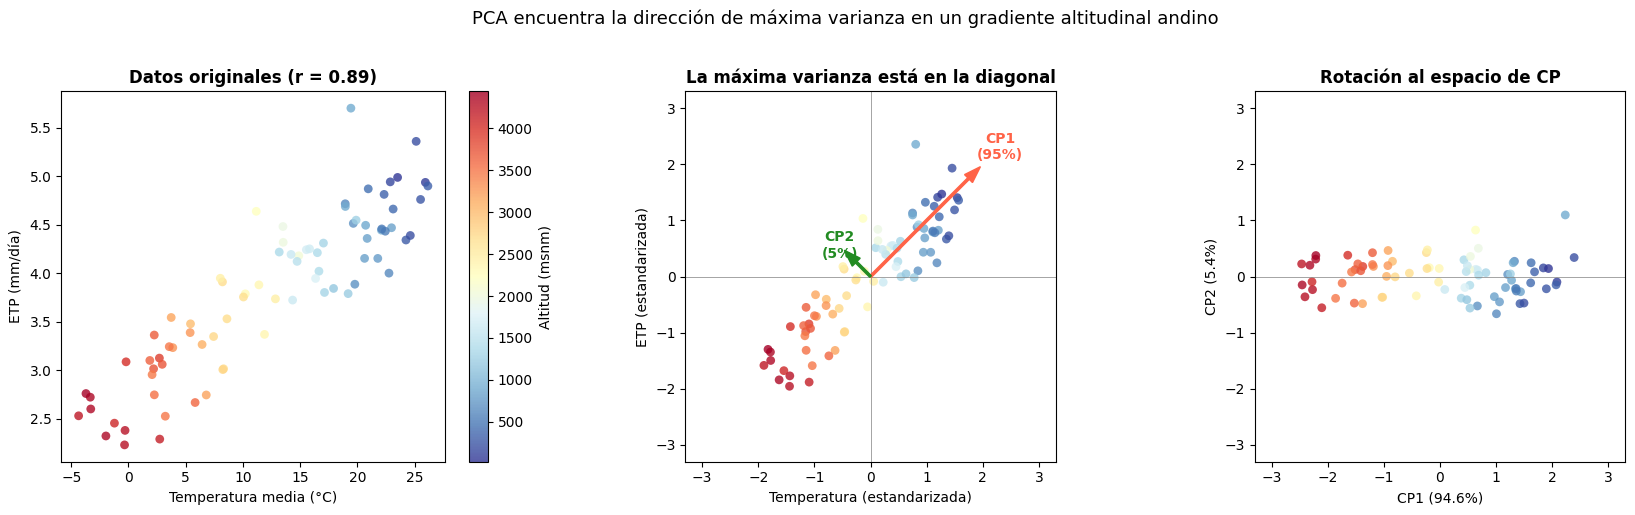

CP1 captura 94.6% de la varianza
CP2 captura 5.4%
→ Si reducimos de 2D a 1D (solo CP1) perdemos apenas 5.4% de la información


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Estaciones sintéticas a lo largo de un gradiente altitudinal andino.
# Temperatura y ETP disminuyen con la altitud → correlación lineal fuerte.
np.random.seed(42)
n = 80
altitud_estacion = np.random.uniform(0, 4500, n)                               # msnm
temperatura = 26 - 0.0065 * altitud_estacion + np.random.normal(0, 1.5, n)     # °C (~6.5 °C/km)
etp         = 4.8 - 0.0005 * altitud_estacion + np.random.normal(0, 0.35, n)   # mm/día

X_clima = np.column_stack([temperatura, etp])
X_clima_e = StandardScaler().fit_transform(X_clima)

pca2d = PCA(n_components=2)
X_pca2d = pca2d.fit_transform(X_clima_e)
# El signo de un CP es arbitrario: lo fijamos para que CP1 crezca con la temperatura
if pca2d.components_[0, 0] < 0:
    pca2d.components_[0] *= -1
    X_pca2d[:, 0] *= -1

r = np.corrcoef(temperatura, etp)[0, 1]
kw = dict(c=altitud_estacion, cmap='RdYlBu_r', s=40, alpha=0.8, edgecolors='none')
fig, ejes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: Datos originales (unidades físicas)
sc = ejes[0].scatter(temperatura, etp, **kw)
plt.colorbar(sc, ax=ejes[0], label='Altitud (msnm)')
ejes[0].set_xlabel('Temperatura media (°C)')
ejes[0].set_ylabel('ETP (mm/día)')
ejes[0].set_title(f'Datos originales (r = {r:.2f})', fontweight='bold')

# Panel 2: Datos estandarizados + direcciones de los CPs
ejes[1].scatter(X_clima_e[:, 0], X_clima_e[:, 1], **kw)
for i, (comp, var) in enumerate(zip(pca2d.components_, pca2d.explained_variance_)):
    L = 2 * np.sqrt(var)                      # flecha = 2 desviaciones estándar a lo largo del CP
    color = 'tomato' if i == 0 else 'forestgreen'
    ejes[1].arrow(0, 0, comp[0] * L, comp[1] * L, color=color, width=0.04,
                  head_width=0.2, length_includes_head=True, zorder=5)
    ejes[1].text(comp[0] * L * 1.18, comp[1] * L * 1.18,
                 f'CP{i+1}\n({pca2d.explained_variance_ratio_[i]:.0%})',
                 fontsize=10, fontweight='bold', color=color, ha='center', va='center')
ejes[1].axhline(0, color='gray', lw=0.5); ejes[1].axvline(0, color='gray', lw=0.5)
ejes[1].set_xlim(-3.3, 3.3); ejes[1].set_ylim(-3.3, 3.3)
ejes[1].set_aspect('equal')
ejes[1].set_xlabel('Temperatura (estandarizada)')
ejes[1].set_ylabel('ETP (estandarizada)')
ejes[1].set_title('La máxima varianza está en la diagonal', fontweight='bold')

# Panel 3: Espacio de componentes principales (misma escala en ambos ejes)
ejes[2].scatter(X_pca2d[:, 0], X_pca2d[:, 1], **kw)
ejes[2].axhline(0, color='gray', lw=0.5)
ejes[2].set_xlim(-3.3, 3.3); ejes[2].set_ylim(-3.3, 3.3)
ejes[2].set_aspect('equal')
ejes[2].set_xlabel(f'CP1 ({pca2d.explained_variance_ratio_[0]:.1%})')
ejes[2].set_ylabel(f'CP2 ({pca2d.explained_variance_ratio_[1]:.1%})')
ejes[2].set_title('Rotación al espacio de CP', fontweight='bold')

plt.suptitle('PCA encuentra la dirección de máxima varianza en un gradiente altitudinal andino',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"CP1 captura {pca2d.explained_variance_ratio_[0]:.1%} de la varianza")
print(f"CP2 captura {pca2d.explained_variance_ratio_[1]:.1%}")
print(f"→ Si reducimos de 2D a 1D (solo CP1) perdemos apenas {pca2d.explained_variance_ratio_[1]:.1%} de la información")

**Los tres paneles cuentan la historia completa:**

1. **Izquierda:** los datos originales. Ambas variables varían; no podemos simplemente descartar una.
2. **Centro:** tras estandarizar, la dirección de **máxima varianza** es la diagonal (flecha roja), una **combinación** de temperatura y ETP. La dirección perpendicular (verde) captura mucho menos.
3. **Derecha:** los datos rotados al espacio de CPs. Casi toda la dispersión está en CP1; CP2 es prácticamente ruido.

**Este es el núcleo de PCA: encontrar ejes nuevos, combinaciones de las variables originales, que capturan la máxima varianza.**

**Observa además:**

- En el panel 2 las flechas son **perpendiculares** (los CPs son ortogonales) y su longitud es proporcional
  a la desviación estándar de los datos en esa dirección.
- En el panel 3 los datos solo se "rotaron": la nube queda estirada a lo largo de CP1 y aplastada en CP2.
  El color (altitud) cambia de forma ordenada **a lo largo de CP1**: CP1 es, en la práctica, un "eje de altitud".

> **Dato curioso:** con **dos** variables estandarizadas, los CPs son **siempre** las diagonales a ±45°.
> Lo que cambia es *cuánta* varianza captura cada uno, que depende solo de la correlación $r$:
> CP1 explica $(1 + |r|)/2$ de la varianza. Con $r = 0$ ambos CPs explican 50% y PCA no sirve para reducir dimensiones.

## 4. ¿Cómo funciona PCA? (conceptual)

PCA tiene tres pasos:

**Paso 1 — Centrar los datos:** restar la media de cada variable para que la nube quede centrada en el origen.
(En la práctica además **estandarizamos**: dividimos por la desviación estándar.)

**Paso 2 — Calcular la matriz de covarianza:** resume cómo varía cada par de variables en conjunto.
La diagonal contiene las **varianzas**; fuera de la diagonal están las **covarianzas**. Con datos estandarizados es la matriz de **correlación**.

**Paso 3 — Obtener eigenvectores y eigenvalores de esa matriz:**
- los **eigenvectores** (vectores propios) son las **direcciones** de los componentes principales;
- los **eigenvalores** (valores propios) indican **cuánta varianza** explica cada componente.

El eigenvector con el eigenvalor más grande es CP1, el siguiente es CP2, y así sucesivamente.
Los **scores** (coordenadas de cada observación en el nuevo sistema) se obtienen proyectando los datos centrados sobre los eigenvectores.

### Terminología clave

| Término | Significado |
|---|---|
| **Componente principal (CP)** | Un nuevo eje: una combinación lineal de las variables originales |
| **Carga (*loading*)** | El peso de cada variable original en un CP (`pca.components_`) |
| **Score** | Coordenada de una observación sobre un CP (`pca.transform(X)`) |
| **Eigenvalor** | La varianza explicada por un CP (`pca.explained_variance_`) |
| **Razón de varianza explicada** | Fracción de la varianza total capturada por un CP (`pca.explained_variance_ratio_`) |
| **Gráfica de Scree** | Barras/línea de eigenvalores: ayuda a decidir cuántos CPs conservar |

Comprobemos que los tres pasos, hechos "a mano" con NumPy, dan exactamente lo mismo que `scikit-learn` con los datos de temperatura y ETP de la sección anterior.

In [4]:
# Paso 1: centrar (y estandarizar)
Xc = (X_clima - X_clima.mean(axis=0)) / X_clima.std(axis=0)

# Paso 2: matriz de covarianza (2 x 2)
cov = np.cov(Xc, rowvar=False)
print("Matriz de covarianza de los datos estandarizados:")
print(cov.round(3))

# Paso 3: eigenvectores y eigenvalores (eigh: para matrices simétricas)
eigval, eigvec = np.linalg.eigh(cov)
orden = np.argsort(eigval)[::-1]               # de mayor a menor varianza
eigval, eigvec = eigval[orden], eigvec[:, orden]

print("\nEigenvalores (a mano):       ", eigval.round(4))
print("explained_variance_ (sklearn):", pca2d.explained_variance_.round(4))
print("\nRazón de varianza explicada:", (eigval / eigval.sum()).round(4))

print("\nEigenvectores (columnas, a mano):")
print(eigvec.round(4))
print("components_ (filas, sklearn):")
print(pca2d.components_.round(4))

# Scores: proyectar los datos centrados sobre los eigenvectores
scores_mano = Xc @ eigvec
iguales = np.allclose(np.abs(scores_mano), np.abs(X_pca2d))
print(f"\n¿Scores iguales a los de sklearn (salvo el signo)? {iguales}")

Matriz de covarianza de los datos estandarizados:
[[1.013 0.903]
 [0.903 1.013]]

Eigenvalores (a mano):        [1.9159 0.1094]
explained_variance_ (sklearn): [1.9159 0.1094]

Razón de varianza explicada: [0.946 0.054]

Eigenvectores (columnas, a mano):
[[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
components_ (filas, sklearn):
[[ 0.7071  0.7071]
 [-0.7071  0.7071]]

¿Scores iguales a los de sklearn (salvo el signo)? True


Los resultados coinciden. Dos detalles:

- El **signo** de un eigenvector es arbitrario (`v` y `-v` son la misma dirección), por eso comparamos en valor absoluto.
- `np.cov` divide por $n-1$, igual que `explained_variance_` de scikit-learn. La suma de los eigenvalores es igual a la varianza
  total, que con datos estandarizados es (casi) el **número de variables**.

## 5. PCA en la práctica: el dataset Iris

Antes de pasar a datos ambientales, veamos el ejemplo clásico. El dataset **Iris** tiene 4 variables (largo y ancho del sépalo
y del pétalo) medidas en 150 flores de 3 especies: imposible de visualizar directamente en un solo gráfico.
PCA puede comprimirlo a 2D conservando casi toda la información.

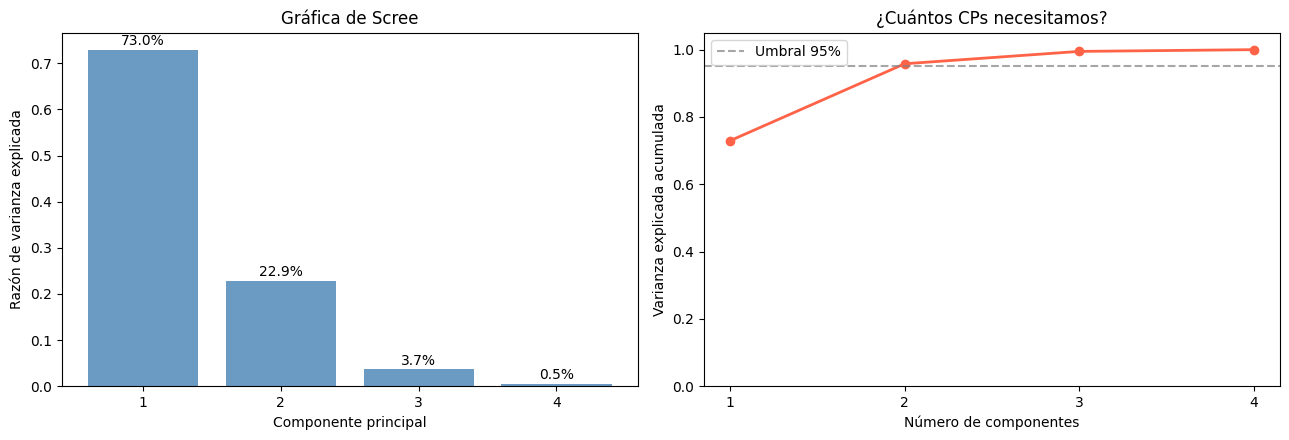

Varianza explicada por CP: [0.73  0.229 0.037 0.005]
Acumulada:                 [0.73  0.958 0.995 1.   ]


In [5]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

# ── Cargar y estandarizar ──
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
nombres_iris = ['largo sépalo', 'ancho sépalo', 'largo pétalo', 'ancho pétalo']

# ¡Siempre estandarizar antes de PCA!
X_iris_e = StandardScaler().fit_transform(X_iris)

# ── Ajustar PCA ──
pca_iris = PCA()
X_pca_iris = pca_iris.fit_transform(X_iris_e)
# Convención de signo (es arbitrario): CP1 crece con el largo del pétalo, CP2 con el ancho del sépalo
for k, j in [(0, 2), (1, 1)]:
    if pca_iris.components_[k, j] < 0:
        pca_iris.components_[k] *= -1
        X_pca_iris[:, k] *= -1

# ── Gráfica de Scree ──
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].bar(range(1, 5), pca_iris.explained_variance_ratio_, color='steelblue', alpha=0.8)
ejes[0].set_xlabel('Componente principal'); ejes[0].set_ylabel('Razón de varianza explicada')
ejes[0].set_title('Gráfica de Scree')
ejes[0].set_xticks(range(1, 5))
for i, v in enumerate(pca_iris.explained_variance_ratio_):
    ejes[0].text(i + 1, v + 0.01, f'{v:.1%}', ha='center', fontsize=10)

var_acum_iris = np.cumsum(pca_iris.explained_variance_ratio_)
ejes[1].plot(range(1, 5), var_acum_iris, 'o-', color='tomato', linewidth=2)
ejes[1].axhline(0.95, color='gray', linestyle='--', alpha=0.7, label='Umbral 95%')
ejes[1].set_xlabel('Número de componentes'); ejes[1].set_ylabel('Varianza explicada acumulada')
ejes[1].set_title('¿Cuántos CPs necesitamos?')
ejes[1].set_xticks(range(1, 5)); ejes[1].set_ylim(0, 1.05); ejes[1].legend()
plt.tight_layout()
plt.show()

print("Varianza explicada por CP:", pca_iris.explained_variance_ratio_.round(3))
print("Acumulada:                ", var_acum_iris.round(3))

CP1 y CP2 juntos capturan ~96% de la varianza total de los datos 4D de Iris: podemos visualizarlos en 2D perdiendo solo ~4% de la información.

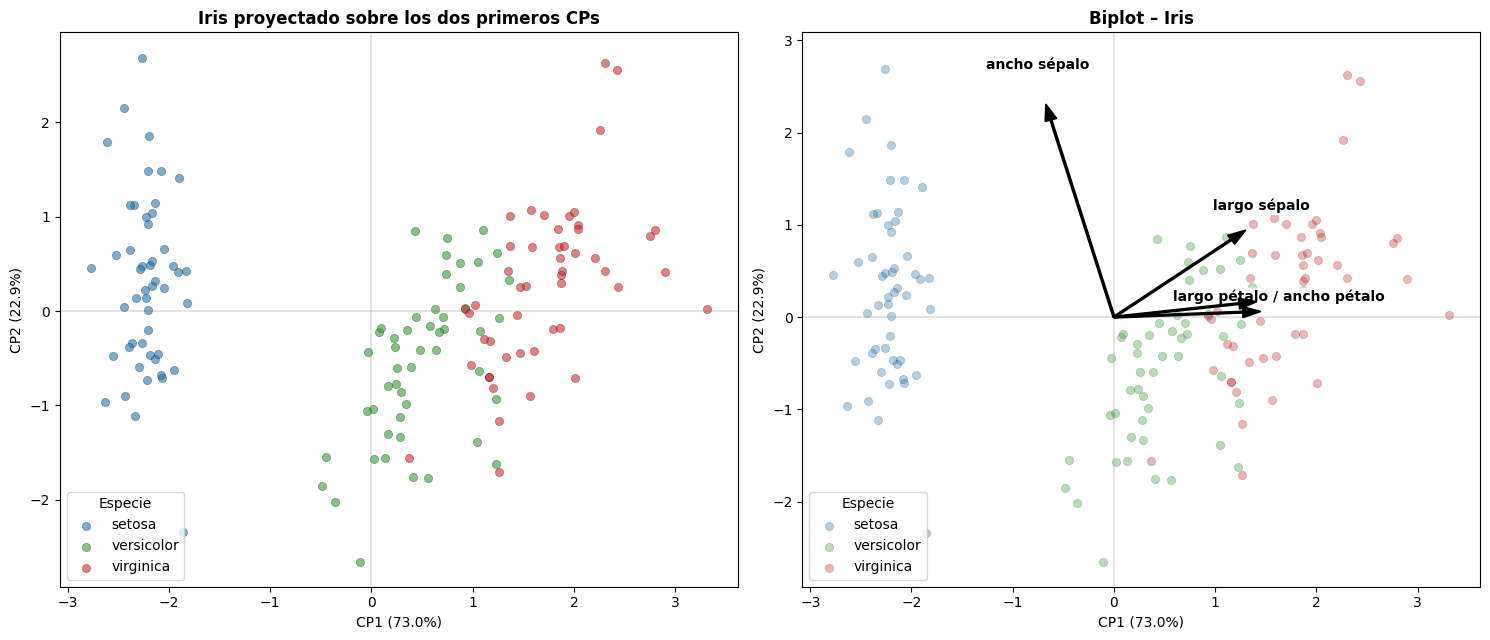

               CP1   CP2
largo sépalo  0.52  0.38
ancho sépalo -0.27  0.92
largo pétalo  0.58  0.02
ancho pétalo  0.56  0.07


In [6]:
especies = ['setosa', 'versicolor', 'virginica']
colores_iris = ['#1f77b4', '#2ca02c', '#d62728']
cargas_iris = pca_iris.components_[:2].T          # (4 variables, 2 CPs)

fig, ejes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax in ejes:
    for i, (nombre, color) in enumerate(zip(especies, colores_iris)):
        m = y_iris == i
        ax.scatter(X_pca_iris[m, 0], X_pca_iris[m, 1], c=color, s=35,
                   alpha=0.6 if ax is ejes[0] else 0.35, edgecolors='k', linewidths=0.3, label=nombre)
    ax.axhline(0, color='gray', linewidth=0.3); ax.axvline(0, color='gray', linewidth=0.3)
    ax.set_xlabel(f'CP1 ({pca_iris.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'CP2 ({pca_iris.explained_variance_ratio_[1]:.1%})')
    ax.legend(title='Especie', loc='lower left')
ejes[0].set_title('Iris proyectado sobre los dos primeros CPs', fontweight='bold')

# Biplot: agregar los vectores de carga (flechas casi paralelas comparten etiqueta)
escala = 2.5
etiquetas = []
for j, nombre in enumerate(nombres_iris):
    x, y = cargas_iris[j, 0] * escala, cargas_iris[j, 1] * escala
    ejes[1].arrow(0, 0, x, y, color='black', width=0.02, head_width=0.12, length_includes_head=True, zorder=5)
    cerca = [e for e in etiquetas if abs(e[0] - x) + abs(e[1] - y) < 0.5]
    if cerca:
        cerca[0][2] += ' / ' + nombre
    else:
        etiquetas.append([x, y, nombre])
for x, y, txt in etiquetas:
    ejes[1].text(x * 1.12, y * 1.12 + 0.15, txt, fontsize=10, fontweight='bold', ha='center', va='center',
                 bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
y0, y1 = ejes[1].get_ylim(); ejes[1].set_ylim(y0, max(y1, cargas_iris[:, 1].max() * escala * 1.12 + 0.5))
ejes[1].set_title('Biplot – Iris', fontweight='bold')
plt.tight_layout()
plt.show()

print(pd.DataFrame(cargas_iris, index=nombres_iris, columns=['CP1', 'CP2']).round(2))

**PCA es no supervisado:** nunca vio las etiquetas de especie (solo usamos `X_iris` para ajustarlo) y, aun así, las tres especies
se separan en el espacio de CPs. *Setosa* queda claramente aparte; *versicolor* y *virginica* se superponen un poco.

### Biplots: interpretar qué significan los CPs

Un gráfico de scores dice *dónde* están las observaciones, pero no *por qué*. El **biplot** agrega los **vectores de carga**:
flechas que muestran cómo contribuye cada variable original a los CPs.

- Una **flecha larga** indica que esa variable influye mucho en los CPs mostrados.
- La **dirección** de la flecha indica sobre qué CP(s) carga.
- Flechas que apuntan en **direcciones parecidas** indican variables **correlacionadas**; flechas **perpendiculares**, variables casi independientes;
  flechas **opuestas**, correlación negativa.

**Cómo leer este biplot:**

- Largo y ancho del pétalo apuntan con fuerza hacia la derecha → dominan **CP1**. CP1 es esencialmente un eje de "tamaño de la flor":
  pétalos grandes a la derecha, pequeños a la izquierda.
- El ancho del sépalo apunta hacia arriba → contribuye sobre todo a **CP2**.
- Las flechas de largo y ancho del pétalo son casi paralelas → esas variables están muy correlacionadas.
- El ancho del sépalo apunta en una dirección muy distinta al largo del pétalo → aportan información independiente.

> **Interpretación ecológica:** PCA no solo comprime datos; revela *qué variables impulsan los principales patrones de variación*.
> En ecología de comunidades, las cargas pueden indicar que el primer eje es un gradiente de humedad y el segundo uno de perturbación.
> Haremos exactamente esto con cuencas peruanas en la sección 9.

## 6. Aplicación ambiental: datos espectrales Landsat

Landsat 8 tiene 6 bandas espectrales. Muchas están correlacionadas (ej. Rojo y Verde se mueven juntas).
PCA comprime las 6 bandas en 2–3 componentes que capturan la mayor parte de la variación espectral.

Un **biplot** superpone dos cosas en el plano CP1–CP2:
- los **puntos** (*scores*): cada pixel proyectado en los CPs;
- las **flechas** (*loadings* o cargas): cuánto aporta cada banda original a cada CP.
  Bandas cuyas flechas apuntan en la misma dirección están positivamente correlacionadas.

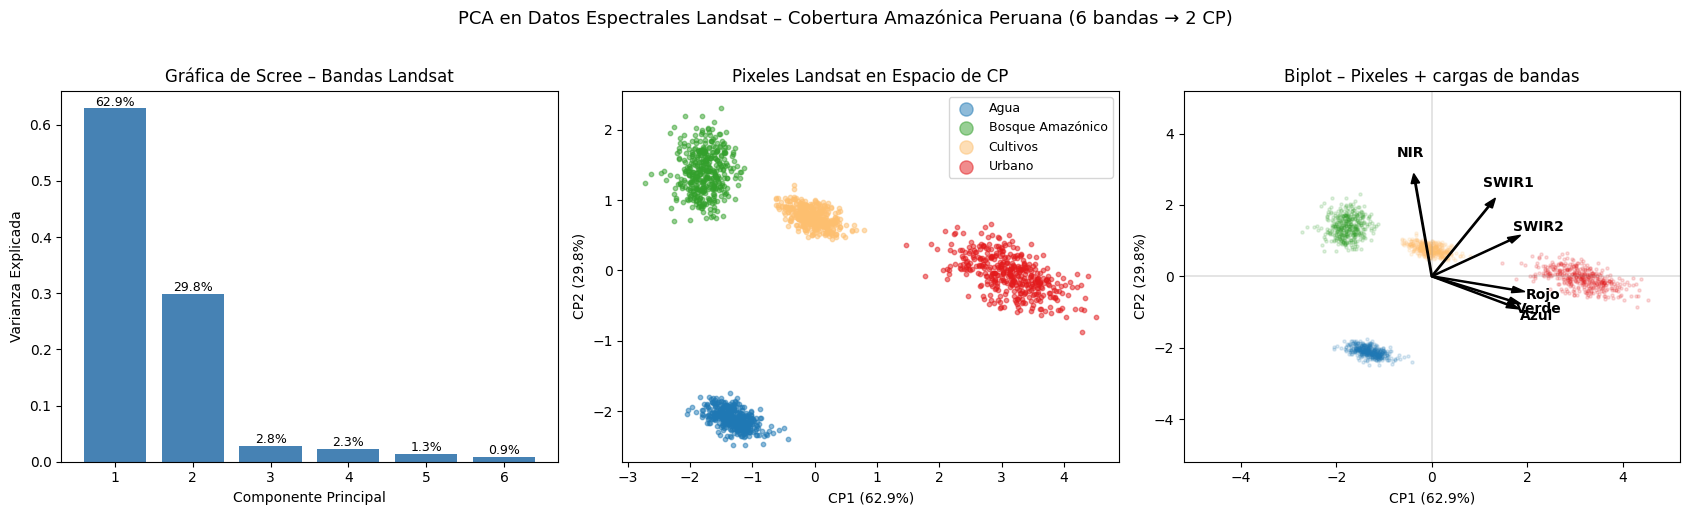

In [7]:
import pandas as pd

np.random.seed(42)
n = 400
nombres_bandas = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']

# Firmas espectrales de coberturas peruanas
agua        = np.random.normal([700, 800, 600, 300, 150, 100], [100]*6, (n, 6))
bos_amazon  = np.random.normal([400, 550, 350, 3800, 1600, 700], [80,80,80,400,300,150], (n, 6))
cultivos    = np.random.normal([700, 800, 700, 2600, 2100, 1100], [100]*6, (n, 6))
urbano      = np.random.normal([1200, 1300, 1400, 1700, 2400, 2100], [200]*6, (n, 6))

X_land = np.vstack([agua, bos_amazon, cultivos, urbano])
y_land = np.array([0]*n + [1]*n + [2]*n + [3]*n)
nombres_clases = ['Agua', 'Bosque Amazónico', 'Cultivos', 'Urbano']
colores_clases = ['#1f78b4', '#33a02c', '#fdbf6f', '#e31a1c']

# Estandarizar y PCA
esc = StandardScaler()
X_land_e = esc.fit_transform(X_land)

pca_land = PCA()
X_pca_land = pca_land.fit_transform(X_land_e)

# El signo de cada CP es arbitrario (puede cambiar entre versiones de scikit-learn).
# Lo fijamos para que la interpretación sea estable: CP1 crece con el Rojo, CP2 con el NIR.
for k, banda in [(0, 'Rojo'), (1, 'NIR')]:
    if pca_land.components_[k, nombres_bandas.index(banda)] < 0:
        pca_land.components_[k] *= -1
        X_pca_land[:, k] *= -1

# Gráfica de Scree
fig, ejes = plt.subplots(1, 3, figsize=(17, 5))

ejes[0].bar(range(1, 7), pca_land.explained_variance_ratio_, color='steelblue')
ejes[0].set_xlabel('Componente Principal')
ejes[0].set_ylabel('Varianza Explicada')
ejes[0].set_title('Gráfica de Scree – Bandas Landsat')
ejes[0].set_xticks(range(1, 7))
for i, v in enumerate(pca_land.explained_variance_ratio_):
    ejes[0].text(i+1, v+0.005, f'{v:.1%}', ha='center', fontsize=9)

# Dispersión CP1 vs CP2
for j, (nombre, color) in enumerate(zip(nombres_clases, colores_clases)):
    mask = y_land == j
    ejes[1].scatter(X_pca_land[mask, 0], X_pca_land[mask, 1],
                    c=color, s=10, alpha=0.5, label=nombre)
ejes[1].set_xlabel(f'CP1 ({pca_land.explained_variance_ratio_[0]:.1%})')
ejes[1].set_ylabel(f'CP2 ({pca_land.explained_variance_ratio_[1]:.1%})')
ejes[1].set_title('Pixeles Landsat en Espacio de CP')
ejes[1].legend(markerscale=3, fontsize=9)

# Biplot: puntos (scores) + flechas (cargas)
for j, color in enumerate(colores_clases):
    mask = y_land == j
    ejes[2].scatter(X_pca_land[mask, 0], X_pca_land[mask, 1], c=color, s=5, alpha=0.15)
cargas = pca_land.components_[:2].T
escala = 4
for j, nombre_banda in enumerate(nombres_bandas):
    ejes[2].arrow(0, 0, cargas[j, 0] * escala, cargas[j, 1] * escala, color='black',
                  width=0.03, head_width=0.18, length_includes_head=True, zorder=5)
    ejes[2].text(cargas[j, 0] * escala * 1.2, cargas[j, 1] * escala * 1.2,
                 nombre_banda, fontsize=10, fontweight='bold', ha='center', va='center')
ejes[2].axhline(0, color='gray', linewidth=0.3)
ejes[2].axvline(0, color='gray', linewidth=0.3)
ejes[2].set_xlabel(f'CP1 ({pca_land.explained_variance_ratio_[0]:.1%})')
ejes[2].set_ylabel(f'CP2 ({pca_land.explained_variance_ratio_[1]:.1%})')
lim = 1.15 * max(np.abs(X_pca_land[:, :2]).max(), np.abs(cargas).max() * escala * 1.3)
ejes[2].set_xlim(-lim, lim); ejes[2].set_ylim(-lim, lim)
ejes[2].set_title('Biplot – Pixeles + cargas de bandas')

plt.suptitle('PCA en Datos Espectrales Landsat – Cobertura Amazónica Peruana (6 bandas → 2 CP)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# Interpretar las cargas
print("Cargas de las bandas en CP1 y CP2:")
print("=" * 40)
df_cargas = pd.DataFrame(
    pca_land.components_[:2].T,
    columns=['CP1', 'CP2'],
    index=nombres_bandas
)
print(df_cargas.round(3))

print("\nVarianza explicada acumulada:")
var_acum = np.cumsum(pca_land.explained_variance_ratio_)
for i, v in enumerate(var_acum):
    print(f"  {i+1} componente(s): {v:.1%}")

print("\nPromedio de cada cobertura en el espacio de CP:")
print(pd.DataFrame(X_pca_land[:, :2], columns=['CP1', 'CP2'])
        .groupby(np.array(nombres_clases)[y_land]).mean().round(2))

Cargas de las bandas en CP1 y CP2:
         CP1    CP2
Azul   0.458 -0.229
Verde  0.467 -0.194
Rojo   0.487 -0.107
NIR   -0.095  0.719
SWIR1  0.333  0.547
SWIR2  0.465  0.287

Varianza explicada acumulada:
  1 componente(s): 62.9%
  2 componente(s): 92.7%
  3 componente(s): 95.5%
  4 componente(s): 97.8%
  5 componente(s): 99.1%
  6 componente(s): 100.0%

Promedio de cada cobertura en el espacio de CP:
                   CP1   CP2
Agua             -1.32 -2.10
Bosque Amazónico -1.77  1.40
Cultivos         -0.04  0.76
Urbano            3.13 -0.05


**Interpretación de los componentes:**

- **CP1 ≈ "brillo" visible + SWIR2.** Azul, Verde, Rojo y SWIR2 cargan positivo y con peso similar; el NIR casi no participa.
  Valores altos = superficies brillantes (**urbano**); valores bajos = superficies oscuras en el visible (**bosque amazónico**).
- **CP2 ≈ "verdor" infrarrojo.** Dominan NIR y SWIR1. Valores altos = vegetación vigorosa (**bosque**, **cultivos**);
  valores bajos = **agua**, que absorbe casi todo el infrarrojo.

Con solo 2 CPs conservamos más del 90% de la información de las 6 bandas.
Recuerda que el **signo** de un CP es arbitrario: lo que importa es qué bandas cargan juntas y cuáles en sentido opuesto.

## 7. PCA + K-Means: una combinación poderosa

PCA y K-Means (Lab 8_1) son un dúo poderoso para análisis ambiental:
1. **PCA reduce dimensiones** → hace K-Means más rápido y mitiga la maldición de la dimensionalidad.
2. **PCA proporciona una vista 2D** → puedes **ver** los grupos que encuentra K-Means.

> Los números de grupo que asigna K-Means son arbitrarios: el "Grupo 0" no tiene por qué ser "Agua".

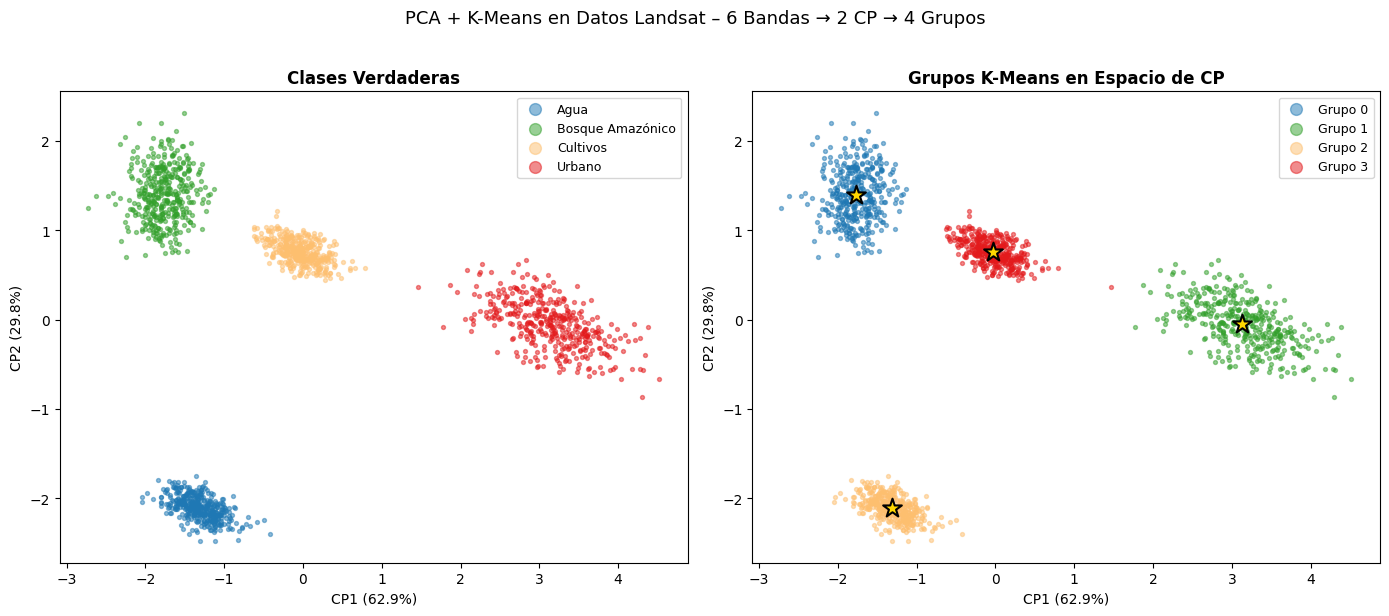

In [13]:
from sklearn.cluster import KMeans

# Aplicar K-Means en espacio de CP
X_2cp = X_pca_land[:, :2]

kmeans_pca = KMeans(n_clusters=4, random_state=42, n_init=10)
grupos_pca = kmeans_pca.fit_predict(X_2cp)

fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
colores_grupos = ['#1f78b4', '#33a02c', '#fdbf6f', '#e31a1c']

# Clases verdaderas
for j, (nombre, color) in enumerate(zip(nombres_clases, colores_clases)):
    mask = y_land == j
    ejes[0].scatter(X_2cp[mask, 0], X_2cp[mask, 1],
                    c=color, s=8, alpha=0.5, label=nombre)
ejes[0].set_title('Clases Verdaderas', fontweight='bold')
ejes[0].legend(markerscale=3, fontsize=9)

# Grupos K-Means
for j in range(4):
    mask = grupos_pca == j
    ejes[1].scatter(X_2cp[mask, 0], X_2cp[mask, 1],
                    c=colores_grupos[j], s=8, alpha=0.5, label=f'Grupo {j}')
centroides_cp = kmeans_pca.cluster_centers_
ejes[1].scatter(centroides_cp[:, 0], centroides_cp[:, 1],
                c='gold', s=200, marker='*', edgecolors='k', linewidths=1.5, zorder=5)
ejes[1].set_title('Grupos K-Means en Espacio de CP', fontweight='bold')
ejes[1].legend(markerscale=3, fontsize=9)

for ax in ejes:
    ax.set_xlabel(f'CP1 ({pca_land.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'CP2 ({pca_land.explained_variance_ratio_[1]:.1%})')

plt.suptitle('PCA + K-Means en Datos Landsat – 6 Bandas → 2 CP → 4 Grupos', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 8. PCA como preprocesamiento para clasificación

PCA puede mejorar la clasificación porque:

1. **Elimina ruido:** los CPs de baja varianza suelen capturar ruido más que señal; descartarlos puede ayudar.
2. **Reduce la multicolinealidad:** variables correlacionadas se convierten en CPs **no correlacionados**. Algunos clasificadores (como Naive Bayes, que asume independencia) se benefician.
3. **Acelera el entrenamiento:** menos variables = algoritmos más rápidos (sobre todo KNN y SVM).

¿Cuánta exactitud perdemos si clasificamos con 2 CPs en lugar de todas las variables? Lo probamos con Landsat (6 bandas) e Iris (4 variables).

Usamos un **`Pipeline`** (estandarizar → PCA → clasificador) para que el escalado y el PCA se ajusten
**solo con los datos de entrenamiento de cada pliegue** de la validación cruzada. Si ajustamos PCA con todos
los datos antes de la validación cruzada, información del conjunto de prueba se "filtra" al modelo (*data leakage*).

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

clasificadores = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes Gaussiano": GaussianNB(),
    "SVM (RBF)": SVC(kernel='rbf'),
}

for titulo, X_d, y_d in [("Landsat (6 bandas)", X_land, y_land), ("Iris (4 variables)", X_iris, y_iris)]:
    print(f"\n{titulo}")
    print(f"{'Clasificador':<25}  {'Todas':>10}  {'2 CPs':>10}")
    print("-" * 48)
    for nombre, clf in clasificadores.items():
        pipe_full = make_pipeline(StandardScaler(), clf)
        pipe_pca  = make_pipeline(StandardScaler(), PCA(n_components=2), clf)
        puntaje_full = cross_val_score(pipe_full, X_d, y_d, cv=5).mean()
        puntaje_pca  = cross_val_score(pipe_pca,  X_d, y_d, cv=5).mean()
        print(f"{nombre:<25}  {puntaje_full:>10.3f}  {puntaje_pca:>10.3f}")

print("\nCuando los 2 primeros CPs capturan la mayor parte de la varianza,")
print("la pérdida de exactitud al reducir dimensiones es mínima.")


Landsat (6 bandas)
Clasificador                    Todas       2 CPs
------------------------------------------------
KNN (k=5)                       1.000       1.000
Naive Bayes Gaussiano           1.000       1.000
SVM (RBF)                       1.000       1.000

Iris (4 variables)
Clasificador                    Todas       2 CPs
------------------------------------------------
KNN (k=5)                       0.960       0.913
Naive Bayes Gaussiano           0.953       0.900
SVM (RBF)                       0.967       0.913

Cuando los 2 primeros CPs capturan la mayor parte de la varianza,
la pérdida de exactitud al reducir dimensiones es mínima.


En Landsat sintético las clases están tan separadas que todos los clasificadores aciertan siempre. En Iris, comprimir de 4 variables a 2 CPs
cambia poco la exactitud porque los 2 primeros CPs capturan ~96% de la varianza. En datos con muchas variables redundantes,
PCA incluso puede *mejorar* la exactitud al eliminar dimensiones ruidosas.

### ¿Cuándo usar PCA como preprocesamiento?

| Situación | ¿Ayuda PCA? |
|---|---|
| Muchas variables correlacionadas (bandas espectrales, variables climáticas) | Sí: reduce la redundancia |
| KNN o K-Means con datos de alta dimensión | Sí: mitiga la maldición de la dimensionalidad |
| Métodos basados en árboles (Random Forest, XGBoost) | Normalmente no: los árboles manejan bien muchas variables y correlaciones |
| Necesitas interpretar variables individuales ("¿qué banda importa?") | Con cuidado: los CPs son mezclas de las variables originales |

---
## 9. Caso real: regionalización de cuencas peruanas con CAMELS-PE

Hasta ahora usamos datos sintéticos. Ahora aplicamos PCA a **datos reales del SENAMHI**.

**Pregunta:** si describimos cada cuenca con ~20 atributos de clima, relieve, cobertura, suelos y geología,
¿cuántas "dimensiones" independientes hay realmente? ¿Qué gradientes físicos dominan? ¿Se agrupan las cuencas por vertiente?

Esto es la base de la **regionalización hidrológica**: agrupar cuencas similares para transferir información
de cuencas aforadas a cuencas **sin estaciones** (que en el Perú son la mayoría).

### El dataset CAMELS-PE

**CAMELS-PE** (*Catchment Attributes and Meteorology for Large-sample Studies – Perú*, SENAMHI, v1.0) reúne
**136 cuencas** con estaciones hidrométricas del SENAMHI, distribuidas en las tres vertientes del país:

| Vertiente | Cuencas |
|---|---|
| Pacífico | 67 |
| Atlántico (Amazonas) | 56 |
| Titicaca | 13 |

Para cada cuenca hay **atributos estáticos** (una fila por cuenca) derivados de productos nacionales e internacionales:

| Grupo | Ejemplos | Fuente |
|---|---|---|
| Clima | `p_mean`, `pet_mean`, `aridity`, `p_seasonality` | PISCOp, PISCOeo_pm |
| Topografía | `area`, `elev_mean`, `slope_mean` | FABDEM |
| Cobertura | `forest_perc`, `agricul_perc`, `non_woody_perc` | MapBiomas |
| Suelos | `inceptisols_perc`, `ultisols_perc`, `entisols_perc` | DSOLMap |
| Geología | `geol_porosity`, `geol_permeability` | GLiM / GLHYMPS |
| Intervención humana | `reservoir_n`, `surface_adh_n` | ANA |
| Firmas hidrológicas | `q_mean`, `runoff_ratio`, `baseflow_index` | SENAMHI / PISCO_ARNOVIC |

Unidades: precipitación, ETP y caudal en **mm/día**; área en km²; elevación en msnm; coberturas y suelos en %.

> El archivo `camels_pe_atributos.csv` une `stations.csv` y los 7 archivos de `02_attributes/` por `gauge_id`.
> El diccionario completo de variables está en `camels_pe_diccionario.csv`.

In [11]:
# ── Cargar atributos de CAMELS-PE (1 fila = 1 cuenca) ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os

# Montar Google Drive en Colab
from google.colab import drive
drive.mount('/content/drive')

# OPCION A: leer el archivo desde la carpeta compartida del curso en tu Drive
fname = '/content/drive/MyDrive/.../CDA_share/1_datasets/CAMELS-PE/camels_pe_atributos.csv'

# OPCION B: si esa carpeta no está en tu Drive, descargar el archivo compartido con gdown
if not os.path.exists(fname):
    import gdown
    ID = "1tVbnC0athzvfe_Ht1GyjfDcg-KUSrzWZ"
    fname = gdown.download(f"https://drive.google.com/uc?id={ID}", "camels_pe_atributos.csv", quiet=False)

camels = pd.read_csv(fname)
print(f"CAMELS-PE: {camels.shape[0]} cuencas x {camels.shape[1]} columnas")
print(camels["gauge_region"].value_counts().to_string())

# Colores por vertiente (paleta apta para daltonismo)
colores_vertiente = {"Pacific": "#E69F00", "Atlantic": "#009E73", "Titicaca": "#0072B2"}
nombres_vertiente = {"Pacific": "Pacífico", "Atlantic": "Atlántico", "Titicaca": "Titicaca"}

camels#[["gauge_id", "gauge_name", "gauge_region", "gauge_lat", "gauge_lon",
       # "p_mean", "aridity", "elev_mean", "forest_perc", "q_mean"]].head()

Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1tVbnC0athzvfe_Ht1GyjfDcg-KUSrzWZ
To: /content/camels_pe_atributos.csv
100%|██████████| 71.2k/71.2k [00:00<00:00, 2.61MB/s]

CAMELS-PE: 136 cuencas x 79 columnas
gauge_region
Pacific     67
Atlantic    56
Titicaca    13


,gauge_id,gauge_name,gauge_region,gauge_lat,gauge_lon,gauge_elev,gauge_record_start,gauge_record_end,gauge_perc_obs,name_cat,...,baseflow_index,slope_fdc,hfd_mean,Q5,Q95,high_q_freq,high_q_dur,low_q_freq,low_q_dur,zero_q_freq
0,PE_472A9204,Chilca,Atlantic,-13.223,-72.343,2770,2017-09-01,2022-09-05,11.07,Cuenca Urubamba,...,0.674,1.128,170.730,0.251,2.762,1.889,4.500,7.556,11.405,0
1,PE_210003,Huancasaya,Titicaca,-15.142,-69.213,4327,2022-03-01,2025-12-31,7.36,Cuenca Suches,...,0.504,2.646,158.595,0.006,3.050,38.333,20.459,163.056,63.034,0
2,PE_204617,Huatiapa,Pacific,-16.009,-72.483,684,1998-01-10,2025-12-31,48.38,Cuenca Camaná,...,0.670,0.813,185.973,0.112,1.385,9.222,9.553,5.722,45.444,0
3,PE_472935F2,Intihuatana Km105,Atlantic,-13.185,-72.524,2166,2012-09-01,2025-12-31,27.23,Cuenca Urubamba,...,0.648,1.497,171.216,0.272,3.394,1.750,4.115,0.889,4.000,0
4,PE_210406,Puente Isla Cabanillas,Titicaca,-15.473,-70.222,3837,1994-07-16,2025-12-31,37.77,Cuenca Coata,...,0.420,1.973,176.811,0.028,3.271,40.583,15.033,133.472,23.276,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,PE_230906,Puente Stuart,Atlantic,-11.802,-75.490,3378,1981-01-01,2023-05-31,67.48,Cuenca Mantaro,...,0.718,0.584,177.378,0.463,3.979,0.833,8.500,0.417,3.750,0
132,PE_251105,Lagarto,Atlantic,-10.607,-73.871,218,2009-03-20,2018-08-31,20.54,Intercuenca Medio Bajo Ucayali,...,0.716,1.515,164.919,0.518,8.626,0.000,NaN,37.722,27.267,0
133,PE_1113355,La Pastora,Atlantic,-12.584,-69.214,200,2004-09-01,2014-03-09,21.15,Intercuenca Medio Alto Madre de Dios,...,0.727,1.141,167.081,0.976,13.769,0.000,NaN,24.500,21.480,0
134,PE_1113346,Napo,Atlantic,-0.917,-75.396,175,2001-03-04,2016-12-31,35.17,Cuenca Napo,...,0.850,0.579,209.270,2.969,16.366,0.000,NaN,0.000,NaN,0


### 9.1 Selección y preparación de variables

#### ¿Por qué solo 19 de las 79 columnas?

`camels_pe_atributos.csv` tiene **79 columnas**, pero solo 19 entran al PCA. PCA necesita variables **numéricas y continuas**
que describan las **características físicas** de la cuenca y que no sean redundantes entre sí. Así se reparten las 79:

| Grupo de columnas | N.º | ¿Entra al PCA? | Motivo |
|---|---|---|---|
| Identificación y metadatos de la estación (`gauge_id`, `gauge_name`, `gauge_lat`, `gauge_lon`, fechas de registro, `nested_group_id`, …) | 15 | No | Describen la **estación**, no la cuenca. `gauge_region`, `gauge_lat` y `gauge_lon` sí los usamos para colorear y hacer mapas |
| Variables categóricas (`high_prec_timing`, `land_dominant_class`, `soil_dominant_class`, `geol_class_1st`, `*_use`, …) | 9 | No | PCA trabaja con números continuos; una categoría ("DJF", "inceptisols") no tiene media ni varianza |
| Firmas hidrológicas (`q_mean`, `runoff_ratio`, `baseflow_index`, `Q95`, …) | 13 | No | Son la **respuesta** de la cuenca (se calculan con el caudal). Las dejamos fuera a propósito para ver después si los CPs las explican (9.8) |
| Intervención humana (`surface_adh_n`, `groundwater_adh_vol`, `reservoir_n`, `reservoir_vol`, …) | 6 | No | No son controles **naturales**; además son muy asimétricas, con muchos ceros, y `reservoir_vol` está vacío en 63 cuencas |
| Atributos físicos excluidos (detalle abajo) | 17 | No | Redundantes, casi siempre cero o con errores |
| **Atributos físicos seleccionados** | **19** | **Sí** | Clima (7), topografía (3), cobertura (4), suelo (3), geología (2) |

**Los 17 atributos físicos que dejamos fuera:**

- **Redundantes:** `elev_median` (r = 0.99 con `elev_mean`), `elev_min` y `elev_max` (la altitud ya está en `elev_mean`),
  `high_prec_dur` (r = 0.87 con otras variables seleccionadas).
- **Con error en el dato:** `perimeter` no es coherente con `area`: en 45 de las 136 cuencas es **menor que el mínimo geométrico posible**. Por ejemplo, una cuenca de ~720 000 km² figura con 100 km de perímetro,
  cuando un círculo de esa área ya tendría ~3 000 km. Al compararlo con los polígonos de `camels_pe_catchments.gpkg`, los perímetros
  parecen estar asignados a otras cuencas. (El área sí coincide con los polígonos.)
- **Casi siempre cero:** `water_perc`, `non_forest_perc`, `non_identi_perc` y los órdenes de suelo minoritarios `aridisols_perc`,
  `gelisols_perc`, `oxisols_perc`, `mollisols_perc`, `vertisols_perc` y `alfisols_perc`. Al **estandarizar**, una variable que es casi siempre 0
  y toma valores altos en 2–3 cuencas se "infla" y puede crear CPs que solo describen a esas pocas cuencas.
  De los suelos conservamos los tres órdenes que dominan alguna cuenca (`soil_dominant_class` solo toma esos tres valores).
- **Geología ligada a clases categóricas:** `geol_class_1st_perc` y `geol_class_2nd_perc` son el % de la clase dominante,
  pero la clase cambia entre cuencas (30% de rocas volcánicas no es comparable con 30% de sedimentarias), e `inter_volca_rocks_perc`
  describe un solo tipo de roca. La geología queda representada por `geol_porosity` y `geol_permeability`, propiedades hidráulicas continuas.

> La selección de variables es una **decisión del analista**, guiada por la pregunta y por el conocimiento del dominio:
> PCA resume lo que le damos, no decide qué es relevante (error común n.º 5, sección 11).

#### Preparación

- `area` va de 68 a 877 000 km² y `aridity` de 0.3 a 16.5: distribuciones muy asimétricas. Aplicamos **log10**
  para que unas pocas cuencas enormes o muy áridas no dominen la varianza.
- Las variables tienen unidades distintas (mm/día, msnm, %, …) → hay que **estandarizar**.

In [14]:
# Clasificación de las 79 columnas de camels_pe_atributos.csv
grupos_columnas = {
    'Metadatos de la estación': ['gauge_id', 'gauge_name', 'gauge_region', 'gauge_lat', 'gauge_lon', 'gauge_elev',
                                 'gauge_record_start', 'gauge_record_end', 'gauge_perc_obs', 'name_cat', 'is_nested',
                                 'nested_group_id', 'nested_group_size', 'downstream_gauge_id', 'upstream_gauge_id'],
    'Categóricas':              ['high_prec_timing', 'low_prec_timing', 'land_dominant_class', 'soil_dominant_class',
                                 'geol_class_1st', 'geol_class_2nd', 'surface_adh_use', 'groundwater_adh_use', 'reservoir_use'],
    'Firmas hidrológicas':      ['q_mean', 'runoff_ratio', 'stream_elas', 'baseflow_index', 'slope_fdc', 'hfd_mean',
                                 'Q5', 'Q95', 'high_q_freq', 'high_q_dur', 'low_q_freq', 'low_q_dur', 'zero_q_freq'],
    'Intervención humana':      ['surface_adh_n', 'surface_adh_vol', 'groundwater_adh_n', 'groundwater_adh_vol',
                                 'reservoir_n', 'reservoir_vol'],
    'Físicas excluidas':        ['elev_median', 'elev_min', 'elev_max', 'high_prec_dur', 'perimeter',
                                 'water_perc', 'non_forest_perc', 'non_identi_perc', 'aridisols_perc', 'gelisols_perc',
                                 'oxisols_perc', 'mollisols_perc', 'vertisols_perc', 'alfisols_perc',
                                 'geol_class_1st_perc', 'geol_class_2nd_perc', 'inter_volca_rocks_perc'],
    'Físicas seleccionadas':    ['p_mean', 'pet_mean', 'aridity', 'p_seasonality', 'high_prec_freq', 'low_prec_freq',
                                 'low_prec_dur', 'elev_mean', 'slope_mean', 'area', 'forest_perc', 'agricul_perc',
                                 'non_woody_perc', 'non_veget_perc', 'inceptisols_perc', 'ultisols_perc',
                                 'entisols_perc', 'geol_porosity', 'geol_permeability'],
}
todas = sum(grupos_columnas.values(), [])
assert sorted(todas) == sorted(camels.columns), "Hay columnas sin clasificar o repetidas"
print(pd.Series({g: len(v) for g, v in grupos_columnas.items()}, name='N.º columnas').to_string())
print(f"Total: {len(todas)}")

# Evidencia 1: variables "casi siempre cero"
casi_cero = ['water_perc', 'non_forest_perc', 'non_identi_perc', 'aridisols_perc', 'gelisols_perc',
             'oxisols_perc', 'mollisols_perc', 'vertisols_perc', 'alfisols_perc']
print("\nMediana (%) de las coberturas y suelos excluidos:")
print(camels[casi_cero].median().round(2).to_string())

# Evidencia 2: el perímetro no es coherente con el área
# El perímetro mínimo posible para un área A es el de un círculo: 2·sqrt(pi·A)
per_min = 2 * np.sqrt(np.pi * camels['area'])
incoherentes = (camels['perimeter'] < per_min).sum()
print(f"\nCuencas con perímetro MENOR que el mínimo geométrico posible: {incoherentes} de {len(camels)}")
print(camels.assign(perimetro_minimo=per_min.round(0))
            .nlargest(3, 'area')[['gauge_id', 'area', 'perimeter', 'perimetro_minimo']].round(0).to_string(index=False))

Metadatos de la estación    15
Categóricas                  9
Firmas hidrológicas         13
Intervención humana          6
Físicas excluidas           17
Físicas seleccionadas       19
Total: 79

Mediana (%) de las coberturas y suelos excluidos:
water_perc         0.11
non_forest_perc    0.00
non_identi_perc    0.00
aridisols_perc     0.02
gelisols_perc      0.01
oxisols_perc       0.06
mollisols_perc     0.00
vertisols_perc     0.00
alfisols_perc      4.77

Cuencas con perímetro MENOR que el mínimo geométrico posible: 45 de 136
  gauge_id     area  perimeter  perimetro_minimo
PE_2401081 877465.0     5315.0            3321.0
 PE_240103 719665.0      100.0            3007.0
 PE_220105 360047.0      478.0            2127.0


Matriz de entrada: 136 cuencas x 19 variables; valores faltantes: 0


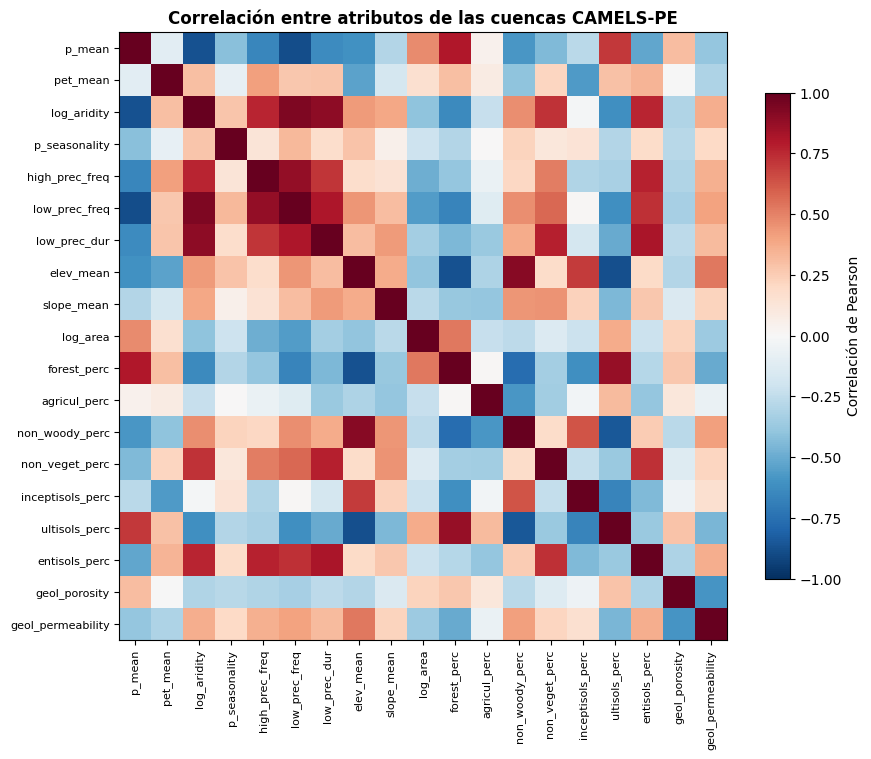

Pares con |r| > 0.6: 34 de 171


In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

vars_pca = {
    'Clima':      ['p_mean', 'pet_mean', 'aridity', 'p_seasonality',
                   'high_prec_freq', 'low_prec_freq', 'low_prec_dur'],
    'Topografía': ['elev_mean', 'slope_mean', 'area'],
    'Cobertura':  ['forest_perc', 'agricul_perc', 'non_woody_perc', 'non_veget_perc'],
    'Suelo':      ['inceptisols_perc', 'ultisols_perc', 'entisols_perc'],
    'Geología':   ['geol_porosity', 'geol_permeability'],
}
cols_pca = sum(vars_pca.values(), [])

X_cam = camels[cols_pca].copy()
X_cam['area'] = np.log10(X_cam['area'])
X_cam['aridity'] = np.log10(X_cam['aridity'])
X_cam = X_cam.rename(columns={'area': 'log_area', 'aridity': 'log_aridity'})
print(f"Matriz de entrada: {X_cam.shape[0]} cuencas x {X_cam.shape[1]} variables; "
      f"valores faltantes: {X_cam.isna().sum().sum()}")

# ¿Están correlacionadas? Si sí, PCA podrá resumirlas en pocos ejes
corr = X_cam.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, ax=ax, label='Correlación de Pearson', shrink=0.8)
ax.set_title('Correlación entre atributos de las cuencas CAMELS-PE', fontweight='bold')
plt.tight_layout()
plt.show()

triu = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Pares con |r| > 0.6: {(triu.abs() > 0.6).sum()} de {len(triu)}")

### 9.2 ¿Cuántos componentes necesitamos?

Tres criterios habituales para decidir cuántos CPs conservar:
1. **Varianza acumulada** ≥ 80–90%.
2. **Criterio de Kaiser:** conservar los CPs con eigenvalor > 1 (explican más que una variable original estandarizada).
3. **Codo** en la gráfica de Scree.

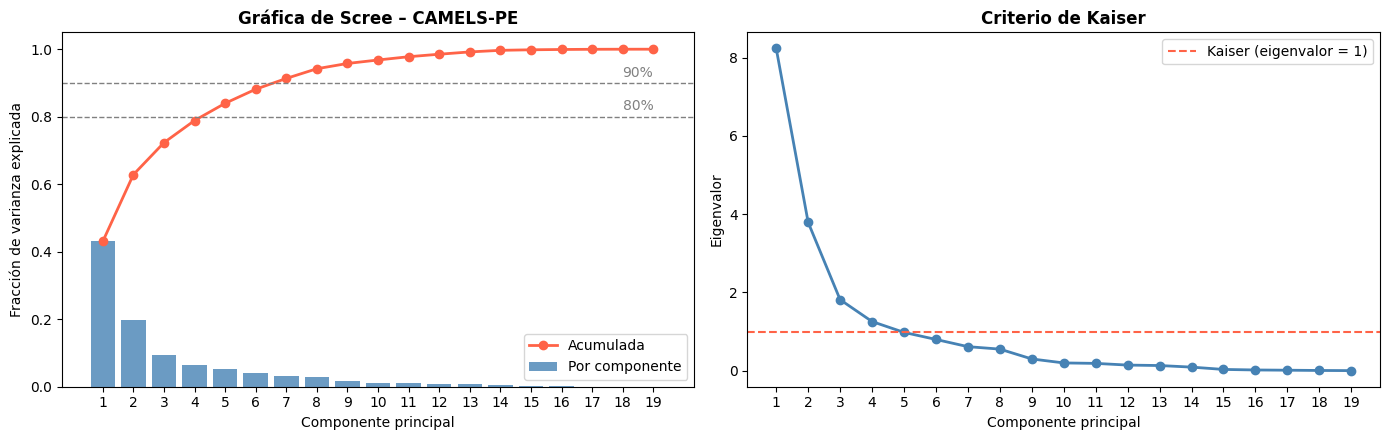

CP1 explica 43.0%, CP2 19.8%, CP3 9.5%
CPs para el 80% de la varianza: 5  (de 19 variables)
CPs para el 90% de la varianza: 7
CPs con eigenvalor > 1 (Kaiser): 4


In [16]:
esc_cam = StandardScaler()
X_cam_e = esc_cam.fit_transform(X_cam)

pca_cam = PCA()
S_cam = pca_cam.fit_transform(X_cam_e)        # scores: coordenadas de cada cuenca en los CPs
nombres_cam = list(X_cam.columns)

# Convención de signos (para que la interpretación no dependa de la versión de scikit-learn):
#   CP1 positivo = cuencas más lluviosas; CP2 positivo = cuencas más altas;
#   CP3 positivo = más agrícolas; CP4 positivo = geología más porosa; CP5 positivo = lluvia más estacional
for k, var in [(0, 'p_mean'), (1, 'elev_mean'), (2, 'agricul_perc'), (3, 'geol_porosity'), (4, 'p_seasonality')]:
    if pca_cam.components_[k, nombres_cam.index(var)] < 0:
        pca_cam.components_[k] *= -1
        S_cam[:, k] *= -1

ratio = pca_cam.explained_variance_ratio_
acum = np.cumsum(ratio)
eig = pca_cam.explained_variance_
k_ejes = np.arange(1, len(ratio) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].bar(k_ejes, ratio, color='steelblue', alpha=0.8, label='Por componente')
ejes[0].plot(k_ejes, acum, 'o-', color='tomato', lw=2, label='Acumulada')
ejes[0].axhline(0.8, color='gray', ls='--', lw=1)
ejes[0].text(len(ratio), 0.81, '80%', ha='right', va='bottom', color='gray')
ejes[0].axhline(0.9, color='gray', ls='--', lw=1)
ejes[0].text(len(ratio), 0.91, '90%', ha='right', va='bottom', color='gray')
ejes[0].set_xlabel('Componente principal'); ejes[0].set_ylabel('Fracción de varianza explicada')
ejes[0].set_title('Gráfica de Scree – CAMELS-PE', fontweight='bold')
ejes[0].set_xticks(k_ejes); ejes[0].legend()

ejes[1].plot(k_ejes, eig, 'o-', color='steelblue', lw=2)
ejes[1].axhline(1, color='tomato', ls='--', lw=1.5, label='Kaiser (eigenvalor = 1)')
ejes[1].set_xlabel('Componente principal'); ejes[1].set_ylabel('Eigenvalor')
ejes[1].set_title('Criterio de Kaiser', fontweight='bold')
ejes[1].set_xticks(k_ejes); ejes[1].legend()
plt.tight_layout()
plt.show()

n80 = int(np.argmax(acum >= 0.80) + 1)
n90 = int(np.argmax(acum >= 0.90) + 1)
n_kaiser = int((eig > 1).sum())
print(f"CP1 explica {ratio[0]:.1%}, CP2 {ratio[1]:.1%}, CP3 {ratio[2]:.1%}")
print(f"CPs para el 80% de la varianza: {n80}  (de {len(ratio)} variables)")
print(f"CPs para el 90% de la varianza: {n90}")
print(f"CPs con eigenvalor > 1 (Kaiser): {n_kaiser}")

#### Decisión: ¿cuántos CPs conservamos?

Los criterios **no coinciden**, y es lo habitual con datos reales:

| Criterio | Idea | CPs |
|---|---|---|
| Varianza acumulada ≥ 80% | Conservar la mayor parte de la información | 5 |
| Varianza acumulada ≥ 90% | Ser más exigente | 7 |
| Kaiser (eigenvalor > 1) | Un CP debe explicar más que una variable original | 4 (CP5 tiene 0.98, en el límite) |
| Codo de la gráfica de Scree | Cortar donde la curva se aplana | 4 o 8: meseta entre CP5 y CP8 y caída clara después de CP8 |
| Análisis paralelo | Conservar los CPs con eigenvalor mayor que el que produciría el **azar** | 3 (ver explicación abajo) |

Elegimos **`n_cp = 5`** como **equilibrio entre criterios**, no por uno solo:
- es el mínimo que supera el **80%** de la varianza (~84%);
- el eigenvalor de CP5 (0.98) es prácticamente 1: el criterio de Kaiser es una regla práctica, no un umbral exacto;
- entre CP5 y CP8 los eigenvalores bajan de forma continua (meseta), así que cortar en 7 u 8 no cambia mucho (CP8 agrega solo ~3%);
- CP5 todavía tiene lectura física (**estacionalidad de la lluvia**); de CP6 en adelante las cargas son mezclas difíciles de interpretar.

Los **4 primeros CPs** son los más explicativos físicamente (humedad, altitud/energía, uso agrícola/tamaño y geología; sección 9.3).
Pasamos de 19 variables correlacionadas a **5 componentes no correlacionados**. Desde aquí, todos los análisis usan `n_cp` CPs.

> **La decisión depende del uso:** para **interpretar** conviene pocos CPs con sentido físico; para **comprimir** los datos
> (por ejemplo, como entrada de otro modelo) se pueden conservar más, hasta el codo (8 CPs ≈ 94%).

#### ¿Qué es el análisis paralelo?

**La pregunta que responde:** ¿este CP describe una estructura **real** de las cuencas, o un eigenvalor así podría aparecer **por casualidad**?

**Una analogía: la moneda.** Lanzas una moneda 10 veces y salen 7 caras. ¿Está cargada? Antes de responder necesitas saber
qué pasa con una moneda **normal**: si lanzas muchas monedas normales 10 veces, 7 caras o más sale con bastante frecuencia (~17% de las veces).
Entonces 7 caras **no** prueba nada. Primero se mide lo que produce el azar, y solo lo que lo supera claramente se considera real.

**Lo mismo pasa con PCA.** Uno esperaría que, si las 19 variables no tuvieran ninguna relación entre sí, todos los eigenvalores fueran 1
(cada CP explicaría lo mismo que una variable). Pero **no es así**: con solo 136 cuencas siempre aparecen correlaciones pequeñas por pura
casualidad, y PCA las aprovecha. El primer CP de datos **sin ninguna estructura** sale con un eigenvalor de ~1.7, y los últimos, de ~0.5.
Por eso el criterio de Kaiser (eigenvalor > 1) puede quedarse con CPs que son solo ruido.

**El procedimiento:**

1. Fabricamos una tabla de **136 filas × 19 columnas llena de números aleatorios** (sorteados de una distribución normal).
   Tiene el mismo tamaño que nuestros datos, pero las columnas **no tienen ninguna relación real** entre sí: es "ruido puro".
2. Le aplicamos exactamente lo mismo que a CAMELS-PE: estandarizar y PCA. Anotamos sus eigenvalores.
3. Repetimos los pasos 1 y 2 **200 veces** (200 tablas de ruido distintas).
4. Para cada posición (CP1, CP2, …) nos quedamos con el **percentil 95** de esos 200 eigenvalores: un valor que el azar
   **casi nunca** supera (solo 5 de cada 100 veces). Es la **línea gris** del gráfico siguiente.
5. **Conservamos solo los CPs reales cuyo eigenvalor supera esa línea**: esos sí reflejan una estructura que el azar no explica.

| | CP1 | CP2 | CP3 | CP4 | CP5 |
|---|---|---|---|---|---|
| Eigenvalor CAMELS-PE | 8.24 | 3.79 | 1.81 | 1.25 | 0.98 |
| Lo que produce el azar (percentil 95) | ~1.87 | ~1.69 | ~1.56 | ~1.46 | ~1.37 |
| ¿Supera al azar? | Sí | Sí | Sí | **No** | **No** |

CP1, CP2 y CP3 superan claramente al azar. CP4 ya no: su eigenvalor (1.25) es **menor** que lo que el ruido puede producir (1.46).

> **Cómo interpretarlo:** el análisis paralelo es el criterio **más exigente**. Que CP4 o CP5 no lo superen **no significa** que sean ruido;
> significa que con solo 136 cuencas **no podemos asegurar** que no lo sean. Por eso lo combinamos con los demás criterios y con el
> sentido físico de las cargas.

La celda siguiente primero muestra **una sola** tabla de ruido para ver que sus eigenvalores no son todos 1, y luego hace las 200 repeticiones.

In [17]:
# Paso 1–2 con UNA sola tabla de ruido: 136 "cuencas" x 19 "variables" sin ninguna relación entre sí
rng = np.random.default_rng(0)
ruido = rng.standard_normal(X_cam.shape)
eig_ruido = PCA().fit(StandardScaler().fit_transform(ruido)).explained_variance_
print(f"Tabla de ruido: {ruido.shape[0]} filas x {ruido.shape[1]} columnas")
print("Eigenvalores del ruido (CP1–CP5):", eig_ruido[:5].round(2))
print("Eigenvalores de CAMELS-PE (CP1–CP5):", eig[:5].round(2))
print("\n→ Aunque el ruido no tiene ninguna estructura, su CP1 supera 1: Kaiser se dejaría engañar.")

Tabla de ruido: 136 filas x 19 columnas
Eigenvalores del ruido (CP1–CP5): [1.7  1.58 1.45 1.39 1.24]
Eigenvalores de CAMELS-PE (CP1–CP5): [8.24 3.79 1.81 1.25 0.98]

→ Aunque el ruido no tiene ninguna estructura, su CP1 supera 1: Kaiser se dejaría engañar.


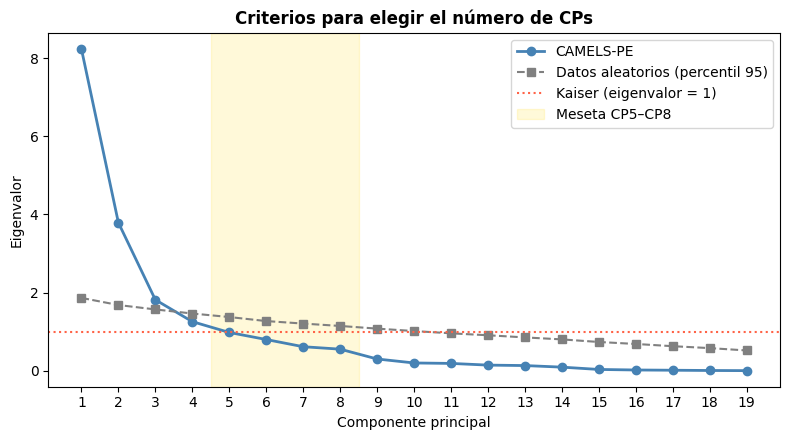

Eigenvalores CP1–CP9: [8.24 3.79 1.81 1.25 0.98 0.8  0.61 0.55 0.3 ]
Kaiser: 4 | Análisis paralelo: 3 | 80%: 5 | 90%: 7

Conservamos 5 CPs → 84.0% de la varianza de 19 variables
Matriz reducida: 136 cuencas x 5 CPs

Los CPs no están correlacionados entre sí:
     CP1  CP2  CP3  CP4  CP5
CP1  1.0  0.0 -0.0 -0.0 -0.0
CP2  0.0  1.0  0.0  0.0 -0.0
CP3 -0.0  0.0  1.0 -0.0 -0.0
CP4 -0.0  0.0 -0.0  1.0 -0.0
CP5 -0.0 -0.0 -0.0 -0.0  1.0


In [18]:
# Pasos 3–5: repetir 200 veces y quedarse con el percentil 95 de los eigenvalores del ruido
rng = np.random.default_rng(42)
eig_azar = np.array([PCA().fit(StandardScaler().fit_transform(rng.standard_normal(X_cam.shape))).explained_variance_
                     for _ in range(200)])
umbral_paralelo = np.percentile(eig_azar, 95, axis=0)
n_paralelo = int(np.cumprod(eig > umbral_paralelo).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_ejes, eig, 'o-', color='steelblue', lw=2, label='CAMELS-PE')
ax.plot(k_ejes, umbral_paralelo, 's--', color='gray', lw=1.5, label='Datos aleatorios (percentil 95)')
ax.axhline(1, color='tomato', ls=':', lw=1.5, label='Kaiser (eigenvalor = 1)')
ax.axvspan(4.5, 8.5, color='gold', alpha=0.15, label='Meseta CP5–CP8')
ax.set_xlabel('Componente principal'); ax.set_ylabel('Eigenvalor'); ax.set_xticks(k_ejes)
ax.set_title('Criterios para elegir el número de CPs', fontweight='bold'); ax.legend()
plt.tight_layout()
plt.show()

print(f"Eigenvalores CP1–CP9: {eig[:9].round(2)}")
print(f"Kaiser: {n_kaiser} | Análisis paralelo: {n_paralelo} | 80%: {n80} | 90%: {n90}")

n_cp = n80               # = 5. Cambia este valor (ej. 4 u 8) y vuelve a ejecutar las celdas siguientes para comparar
S_cp = S_cam[:, :n_cp]   # scores de las 136 cuencas en los CPs retenidos
nombres_cp = [f'CP{k+1}' for k in range(n_cp)]

print(f"\nConservamos {n_cp} CPs → {acum[n_cp - 1]:.1%} de la varianza de {len(ratio)} variables")
print(f"Matriz reducida: {S_cp.shape[0]} cuencas x {S_cp.shape[1]} CPs")
print("\nLos CPs no están correlacionados entre sí:")
print(pd.DataFrame(S_cp, columns=nombres_cp).corr().round(2))

### 9.3 Biplot: ¿qué gradientes físicos describen las cuencas peruanas?

El biplot muestra el plano CP1–CP2 (los dos CPs más importantes); el mapa de calor muestra las cargas de los **`n_cp` CPs retenidos**.

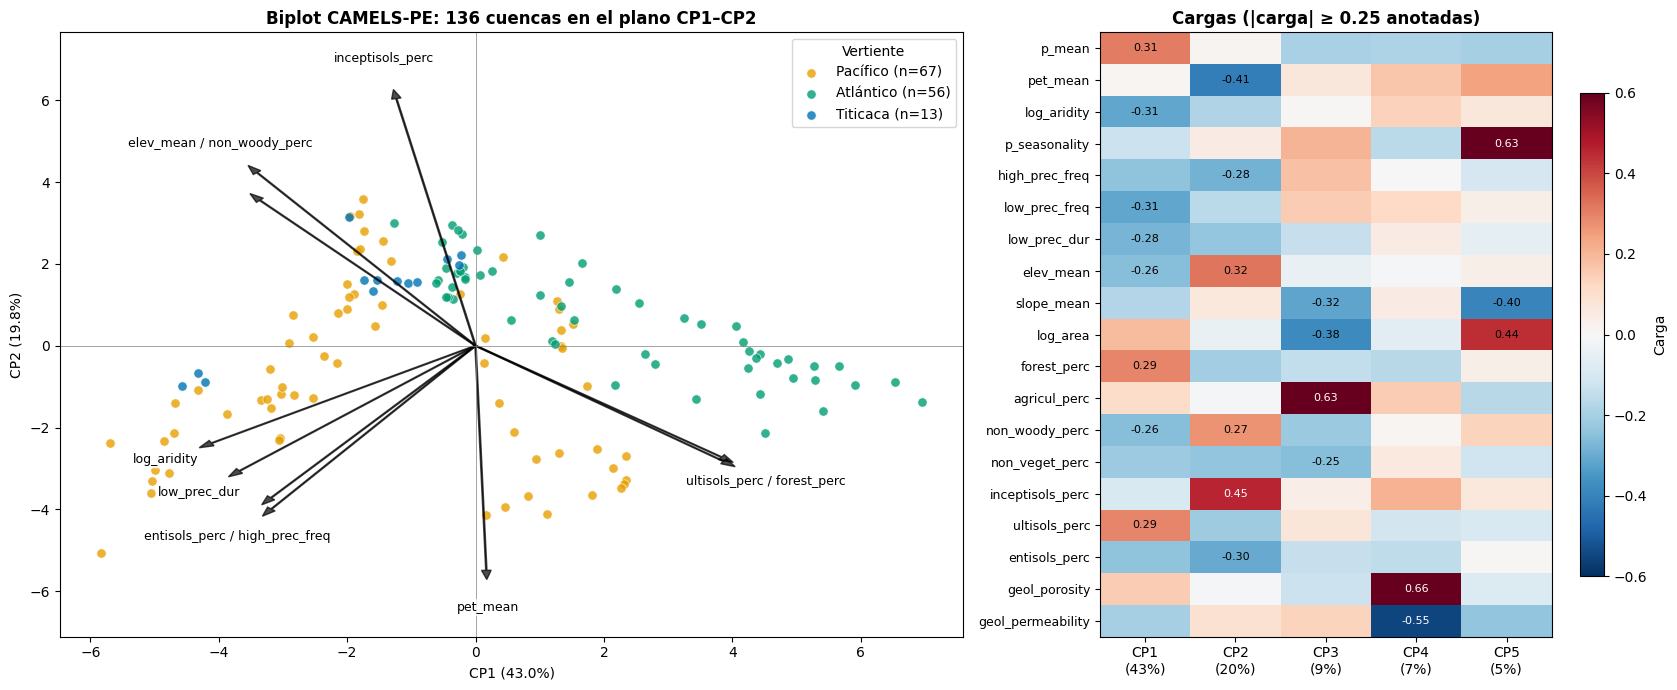

Promedio de scores por vertiente:
            CP1   CP2   CP3   CP4   CP5
Atlántico  2.08  0.70 -0.25 -0.03  0.06
Pacífico  -1.38 -0.83  0.11  0.16 -0.13
Titicaca  -1.85  1.24  0.50 -0.68  0.44


In [19]:
cargas_cam = pd.DataFrame(pca_cam.components_[:n_cp].T, index=nombres_cam, columns=nombres_cp)

fig, ejes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.6, 1]})

# Biplot: cuencas coloreadas por vertiente + flechas de las 10 variables con más peso en CP1–CP2
ax = ejes[0]
for reg, color in colores_vertiente.items():
    m = (camels['gauge_region'] == reg).values
    ax.scatter(S_cam[m, 0], S_cam[m, 1], c=color, s=45, alpha=0.8,
               edgecolors='white', linewidths=0.5, label=f'{nombres_vertiente[reg]} (n={m.sum()})')
peso = np.hypot(cargas_cam['CP1'], cargas_cam['CP2'])
escala = 0.9 * np.abs(S_cam[:, :2]).max() / np.abs(cargas_cam[['CP1', 'CP2']].values).max()
etiquetas = []   # [x, y, texto]; flechas casi idénticas comparten una sola etiqueta
for var in peso.sort_values(ascending=False).index[:10]:
    x, y = cargas_cam.loc[var, 'CP1'] * escala, cargas_cam.loc[var, 'CP2'] * escala
    ax.arrow(0, 0, x, y, color='black', alpha=0.7, width=0.02, head_width=0.15, length_includes_head=True)
    cerca = [e for e in etiquetas if np.hypot(e[0] - x, e[1] - y) < 0.8]
    if cerca:
        cerca[0][2] += ' / ' + var
    else:
        etiquetas.append([x, y, var])
for x, y, txt in etiquetas:
    ax.text(x * 1.12, y * 1.12, txt, fontsize=9, ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
y0, y1 = ax.get_ylim(); ax.set_ylim(y0 - 0.8, y1 + 0.8)
ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
ax.set_xlabel(f'CP1 ({ratio[0]:.1%})'); ax.set_ylabel(f'CP2 ({ratio[1]:.1%})')
ax.set_title('Biplot CAMELS-PE: 136 cuencas en el plano CP1–CP2', fontweight='bold')
ax.legend(title='Vertiente', loc='best')

# Mapa de calor de cargas de los n_cp CPs retenidos
ax = ejes[1]
im = ax.imshow(cargas_cam.values, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
ax.set_xticks(range(n_cp)); ax.set_xticklabels([f'CP{i+1}\n({ratio[i]:.0%})' for i in range(n_cp)])
ax.set_yticks(range(len(nombres_cam))); ax.set_yticklabels(nombres_cam, fontsize=9)
for i in range(len(nombres_cam)):
    for j in range(n_cp):
        v = cargas_cam.values[i, j]
        if abs(v) >= 0.25:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(v) > 0.45 else 'black')
plt.colorbar(im, ax=ax, label='Carga', shrink=0.8)
ax.set_title('Cargas (|carga| ≥ 0.25 anotadas)', fontweight='bold')
plt.tight_layout()
plt.show()

print("Promedio de scores por vertiente:")
print(pd.DataFrame(S_cp, columns=nombres_cp)
        .groupby(camels['gauge_region'].map(nombres_vertiente).values).mean().round(2))

**Interpretación física:**

- **CP1 ≈ gradiente de humedad "Amazonía ↔ costa/altiplano".** Cargan positivo `p_mean`, `forest_perc` y `ultisols_perc`
  (suelos tropicales muy meteorizados); cargan negativo `log_aridity`, la frecuencia de días secos, `non_woody_perc`
  (pajonal, matorral) y `entisols_perc`. Las cuencas **atlánticas** quedan a la derecha; las del **Pacífico** y el **Titicaca**, a la izquierda.
- **CP2 ≈ gradiente de altitud / energía.** Carga positivo `elev_mean` e `inceptisols_perc`, y negativo `pet_mean`.
  Separa las cuencas altoandinas frías (**Titicaca**) de las cuencas costeras cálidas con alta ETP (**Pacífico**).
- **CP3 ≈ cuencas agrícolas pequeñas ↔ cuencas grandes y empinadas.** Domina `agricul_perc` (positivo), con `log_area` y `slope_mean` en sentido opuesto.
- **CP4 ≈ geología.** Lo forman casi solo `geol_porosity` (positivo) y `geol_permeability` (negativo): un eje independiente del clima.
- **CP5 ≈ estacionalidad de la lluvia.** Domina `p_seasonality` (positivo), acompañado de `log_area` y de `slope_mean` en sentido opuesto. Explica solo ~5%.

En otras palabras, \~60% de la variabilidad de 19 atributos se resume en dos ejes que cualquier hidrólogo peruano reconocería:
**¿cuánta agua hay?** y **¿a qué altura / con cuánta energía?** CP3 y CP4 agregan uso del suelo y geología (\~79%), y CP5 la estacionalidad (~84%).

### 9.4 Explorar las dimensiones de forma interactiva

Un biplot 2D solo muestra CP1 y CP2 (~63%). Para "ver" más dimensiones usamos gráficos interactivos con **plotly**:

1. **Biplot 3D (CP1–CP3):** arrástralo con el mouse para rotarlo y usa la rueda para acercarte. Pasa el cursor sobre una cuenca para ver su nombre y sus scores.
   Con el menú puedes cambiar el **color** entre la vertiente y los scores de CP4 o CP5: el color agrega una 4.ª dimensión.
   Las líneas negras son las cargas de las variables con más peso (como las flechas del biplot 2D).
2. **Matriz de dispersión:** todos los pares de CPs retenidos. Selecciona cuencas con el lazo o el rectángulo en un panel
   y se resaltan en todos los demás.

> ¿Por qué no un gráfico "4D" o "5D"? Más allá de 3 ejes espaciales hay que codificar dimensiones con color, tamaño o forma, y se leen mal.
> La matriz de dispersión es la forma honesta de ver todas las dimensiones a la vez.

In [20]:
import plotly.graph_objects as go

hover = [f"{n} ({i})<br>{nombres_vertiente[r]}" for n, i, r in
         zip(camels['gauge_name'], camels['gauge_id'], camels['gauge_region'])]
hover_cp = [h + '<br>' + '<br>'.join(f'CP{k+1} = {S_cp[j, k]:.2f}' for k in range(n_cp))
            for j, h in enumerate(hover)]

trazas, grupo_traza = [], []
# (a) color por vertiente
for reg, color in colores_vertiente.items():
    m = (camels['gauge_region'] == reg).values
    trazas.append(go.Scatter3d(x=S_cp[m, 0], y=S_cp[m, 1], z=S_cp[m, 2], mode='markers',
                               name=nombres_vertiente[reg], text=np.array(hover_cp)[m], hoverinfo='text',
                               marker=dict(size=5, color=color, line=dict(width=0.5, color='white'))))
    grupo_traza.append('vertiente')
# (b) color continuo por CP4, CP5, … (4.ª y 5.ª dimensión)
for k in range(3, n_cp):
    lim = np.abs(S_cp[:, k]).max()
    trazas.append(go.Scatter3d(x=S_cp[:, 0], y=S_cp[:, 1], z=S_cp[:, 2], mode='markers', name=f'CP{k+1}',
                               text=hover_cp, hoverinfo='text', visible=False, showlegend=False,
                               marker=dict(size=5, color=S_cp[:, k], colorscale='RdBu_r', cmin=-lim, cmax=lim,
                                           colorbar=dict(title=f'CP{k+1}'), line=dict(width=0.5, color='white'))))
    grupo_traza.append(f'CP{k+1}')
# (c) cargas: líneas desde el origen para las 8 variables con más peso en CP1–CP3
peso3 = np.sqrt((cargas_cam[['CP1', 'CP2', 'CP3']] ** 2).sum(axis=1))
esc3 = 0.8 * np.abs(S_cp[:, :3]).max() / np.abs(cargas_cam[['CP1', 'CP2', 'CP3']].values).max()
for var in peso3.sort_values(ascending=False).index[:8]:
    x, y, z = cargas_cam.loc[var, ['CP1', 'CP2', 'CP3']] * esc3
    trazas.append(go.Scatter3d(x=[0, x], y=[0, y], z=[0, z], mode='lines+text', text=['', var],
                               textposition='top center', line=dict(color='black', width=4),
                               hoverinfo='skip', showlegend=False))
    grupo_traza.append('cargas')

def visibles(opcion):
    return [g == opcion or g == 'cargas' for g in grupo_traza]

botones = [dict(label='Color: vertiente', method='update', args=[{'visible': visibles('vertiente')}])]
botones += [dict(label=f'Color: score CP{k+1}', method='update', args=[{'visible': visibles(f'CP{k+1}')}])
            for k in range(3, n_cp)]

fig3d = go.Figure(trazas)
fig3d.update_layout(
    title='Biplot 3D interactivo – CAMELS-PE (CP1–CP3)',
    scene=dict(xaxis_title=f'CP1 ({ratio[0]:.0%}) humedad', yaxis_title=f'CP2 ({ratio[1]:.0%}) altitud',
               zaxis_title=f'CP3 ({ratio[2]:.0%}) agrícola'),
    updatemenus=[dict(buttons=botones, direction='down', x=0.0, y=1.08, xanchor='left')],
    legend=dict(title='Vertiente', x=0.85, y=0.9), height=650, margin=dict(l=0, r=0, t=60, b=0))
fig3d.show()

In [ ]:
import plotly.express as px

df_cp = pd.DataFrame(S_cp, columns=nombres_cp)
df_cp['Vertiente'] = camels['gauge_region'].map(nombres_vertiente).values
df_cp['Cuenca'] = camels['gauge_name'].values

fig_splom = px.scatter_matrix(df_cp, dimensions=nombres_cp, color='Vertiente', hover_name='Cuenca',
                              color_discrete_map={nombres_vertiente[k]: v for k, v in colores_vertiente.items()},
                              title=f'Matriz de dispersión de los {n_cp} CPs retenidos (selecciona cuencas con el lazo)')
fig_splom.update_traces(diagonal_visible=False, showupperhalf=False, marker=dict(size=4, opacity=0.8))
fig_splom.update_layout(height=750, dragmode='select')
fig_splom.show()

**Qué observar:**

- En 3D, las cuencas del **Titicaca** forman un grupo compacto en la parte alta de CP2, cerca de las cabeceras atlánticas y del Pacífico sur:
  comparten altitud, pajonal y lluvia estacional.
- Con color por **CP4** (geología) aparecen cuencas que en CP1–CP3 parecían iguales pero tienen geología distinta: es información que el biplot 2D esconde.
- En la matriz de dispersión, los paneles con **CP4 y CP5** muestran las vertientes muy superpuestas: esos ejes describen sobre todo
  variaciones *dentro* de cada vertiente. Solo el Titicaca se desplaza un poco (CP4 más bajo, CP5 más alto).

### 9.5 Los componentes en el mapa

Los scores son números por cuenca, así que podemos mapearlos usando la ubicación de cada estación. Mapeamos los `n_cp` CPs retenidos.

In [21]:
# ── Capa de países (Natural Earth, escala 1:50 millones) ──
import geopandas as gpd

fuentes_paises = [
    "https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip",
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson",
]
paises = None
for url in fuentes_paises:
    try:
        paises = gpd.read_file(url)[['ADMIN', 'NAME_ES', 'geometry']]
        break
    except Exception as e:
        print(f"No se pudo descargar {url}: {e}")

extension_peru = dict(xlim=(-81.8, -68.2), ylim=(-18.8, 0.3))

def agregar_paises(ax):
    """Dibuja los países de fondo, resalta el borde del Perú y ajusta la extensión del mapa."""
    if paises is not None:
        paises.plot(ax=ax, color='#f0f0f0', edgecolor='#9e9e9e', linewidth=0.6, zorder=0)
        paises[paises['ADMIN'] == 'Peru'].plot(ax=ax, color='white', edgecolor='black', linewidth=1.0, zorder=0.5)
        for nombre, (x, y) in {'ECUADOR': (-79.3, -1.2), 'COLOMBIA': (-71.5, -0.6), 'BRASIL': (-69.3, -8.5),
                               'BOLIVIA': (-68.9, -15.8), 'CHILE': (-69.6, -18.4), 'OCÉANO\nPACÍFICO': (-80.5, -15.0)}.items():
            ax.text(x, y, nombre, fontsize=8, color='#757575', ha='center', va='center', style='italic', zorder=0.6)
    ax.set_xlim(*extension_peru['xlim']); ax.set_ylim(*extension_peru['ylim'])
    ax.set_aspect('equal')

print("Capa de países cargada:", paises is not None)

Capa de países cargada: True


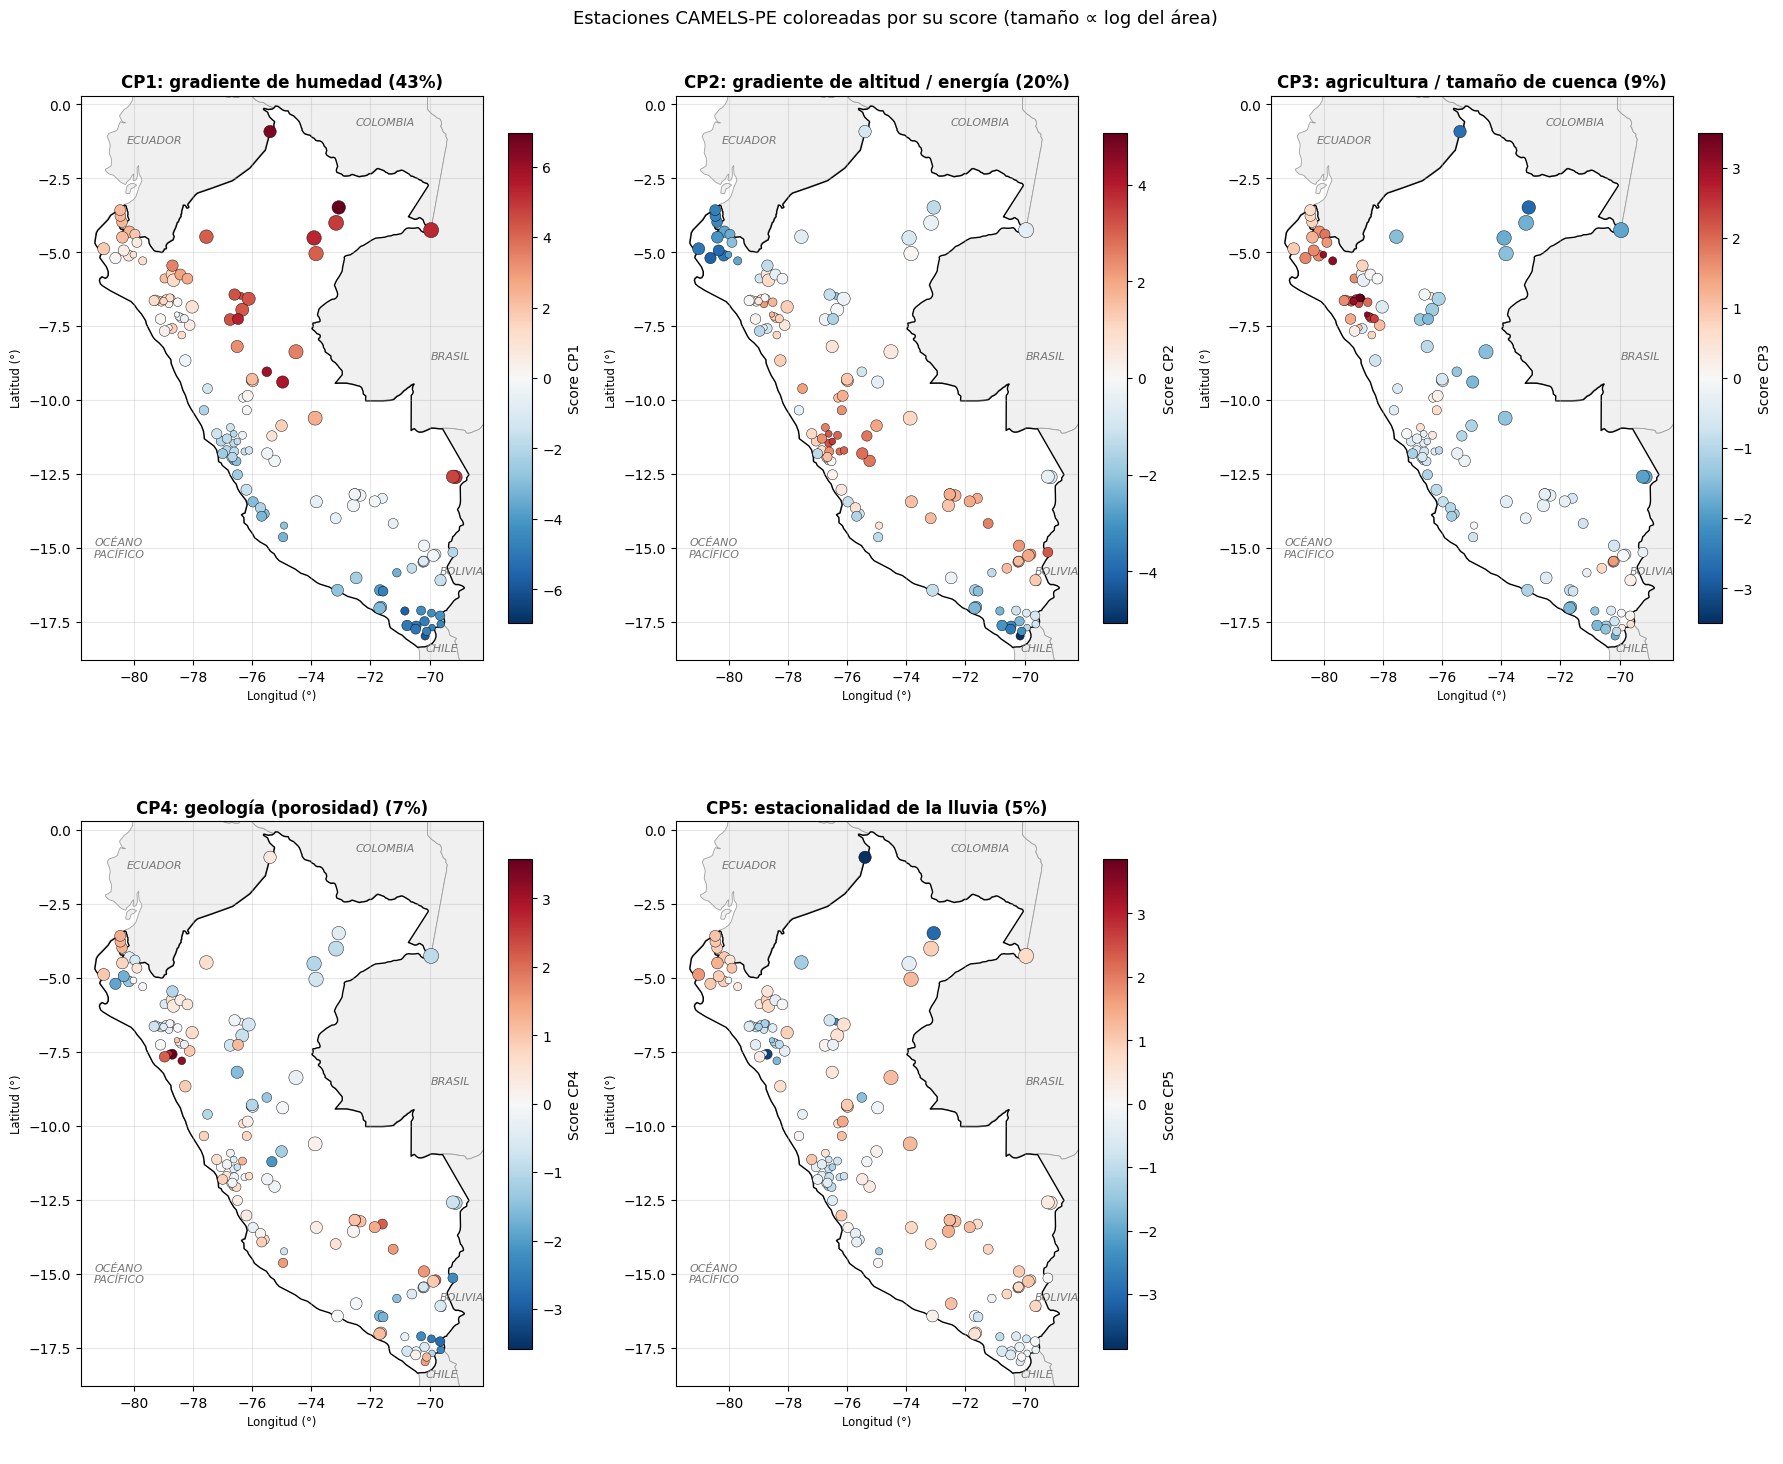

In [22]:
titulos_cp = {0: 'CP1: gradiente de humedad', 1: 'CP2: gradiente de altitud / energía',
              2: 'CP3: agricultura / tamaño de cuenca', 3: 'CP4: geología (porosidad)',
              4: 'CP5: estacionalidad de la lluvia'}
n_col = 3
n_fil = int(np.ceil(n_cp / n_col))
fig, ejes = plt.subplots(n_fil, n_col, figsize=(18, 7.5 * n_fil), squeeze=False)
tam = 15 + 25 * (X_cam['log_area'] - X_cam['log_area'].min())   # tamaño ~ log(área)
for k, ax in enumerate(ejes.flat):
    if k >= n_cp:
        ax.axis('off'); continue
    agregar_paises(ax)
    lim = np.abs(S_cp[:, k]).max()
    sc = ax.scatter(camels['gauge_lon'], camels['gauge_lat'], c=S_cp[:, k], cmap='RdBu_r',
                    vmin=-lim, vmax=lim, s=tam, edgecolors='k', linewidths=0.3, zorder=3)
    plt.colorbar(sc, ax=ax, label=f'Score CP{k+1}', shrink=0.7)
    ax.set_xlabel('Longitud (°)'); ax.set_ylabel('Latitud (°)')
    ax.grid(alpha=0.3)
    ax.set_title(f"{titulos_cp.get(k, f'CP{k+1}')} ({ratio[k]:.0%})", fontweight='bold')
plt.suptitle('Estaciones CAMELS-PE coloreadas por su score (tamaño ∝ log del área)', fontsize=13)
plt.tight_layout()
plt.show()

### 9.6 PCA + K-Means: regiones hidroclimáticas

Agrupamos las cuencas con K-Means usando los **`n_cp` CPs retenidos en 9.2** (en lugar de las 19 variables correlacionadas).
Como los scores conservan la escala de cada CP, CP1 (el de mayor varianza) pesa más en las distancias, como debe ser. Elegimos $k$ con el coeficiente de silueta (Lab 8_1).

Silueta por k: {2: np.float64(0.341), 3: np.float64(0.369), 4: np.float64(0.392), 5: np.float64(0.406), 6: np.float64(0.362), 7: np.float64(0.354)}
k elegido: 5


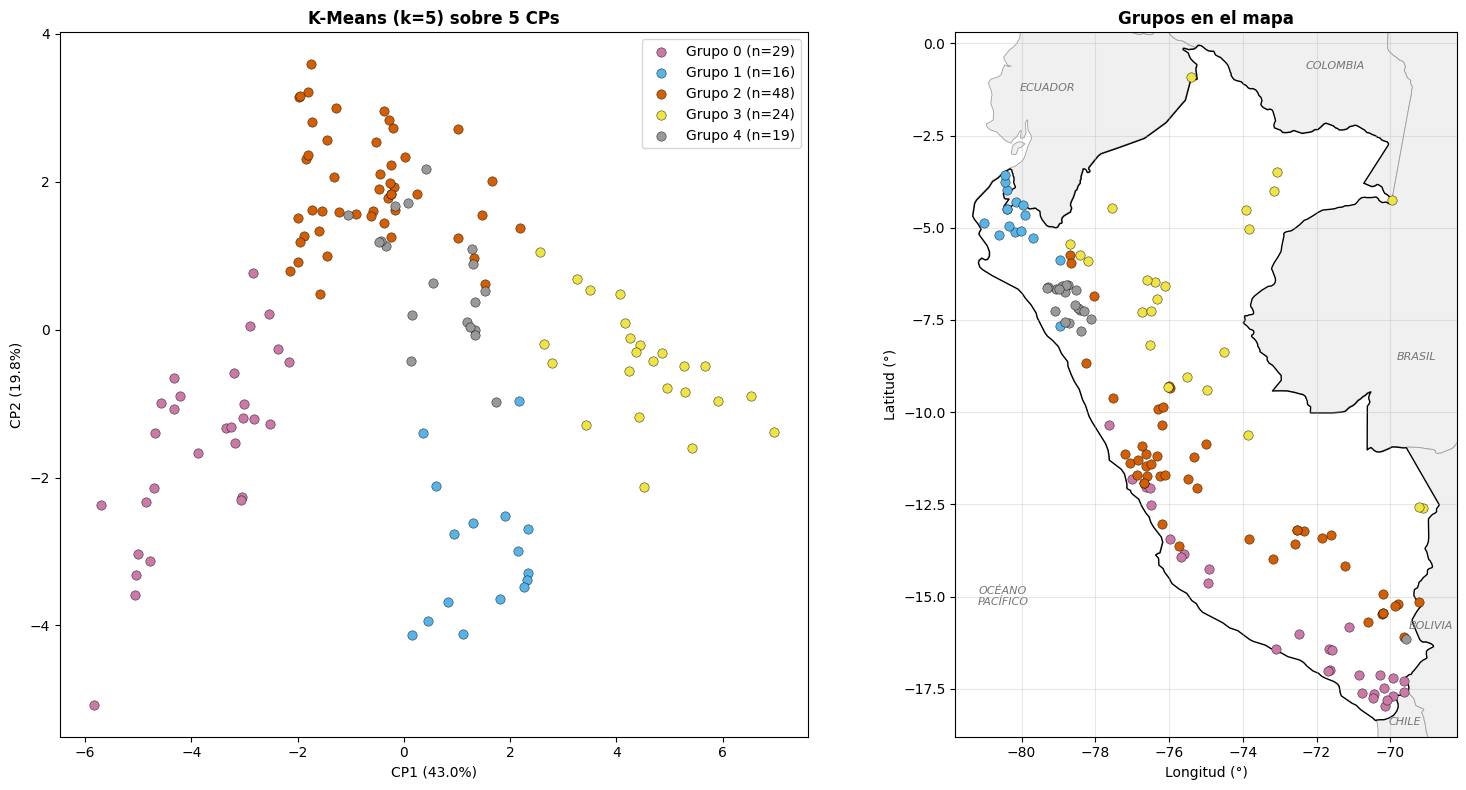


Grupos vs. vertiente:
gauge_region  Atlántico  Pacífico  Titicaca
grupo_pca                                  
0                     0        26         3
1                     1        15         0
2                    23        16         9
3                    24         0         0
4                     8        10         1

Perfil medio de cada grupo:
           p_mean  pet_mean  aridity  elev_mean  forest_perc  q_mean  \
grupo_pca                                                              
0            1.05      3.66     4.65    3780.69         0.80    0.32   
1            2.71      4.08     1.66    1373.50        48.05    1.22   
2            2.50      3.29     1.43    4080.50         5.70    0.98   
3            7.18      3.49     0.54    1665.94        67.95    4.03   
4            2.87      3.33     1.21    3000.62         6.24    1.23   

           runoff_ratio  
grupo_pca                
0                  0.30  
1                  0.44  
2                  0.38  
3    

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Z = S_cp
siluetas = {k: silhouette_score(Z, KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Z))
            for k in range(2, 8)}
print("Silueta por k:", {k: round(v, 3) for k, v in siluetas.items()})

k_opt = max(siluetas, key=siluetas.get)   # k con la mayor silueta (prueba también otros valores)
# k_opt = 7 ################################## VARIABLE K #################################################
print(f"k elegido: {k_opt}")
km_cam = KMeans(n_clusters=k_opt, n_init=20, random_state=42)
grupo_cam = km_cam.fit_predict(Z)
camels['grupo_pca'] = grupo_cam

colores_grupo = ['#CC79A7', '#56B4E9', '#D55E00', '#F0E442', '#999999', '#000000', '#009E73']
fig, ejes = plt.subplots(1, 2, figsize=(16, 8))
for g in range(k_opt):
    m = grupo_cam == g
    ejes[0].scatter(S_cam[m, 0], S_cam[m, 1], c=colores_grupo[g], s=45, edgecolors='k',
                    linewidths=0.3, label=f'Grupo {g} (n={m.sum()})')
    ejes[1].scatter(camels.loc[m, 'gauge_lon'], camels.loc[m, 'gauge_lat'], c=colores_grupo[g],
                    s=45, edgecolors='k', linewidths=0.3, zorder=3)
ejes[0].set_xlabel(f'CP1 ({ratio[0]:.1%})'); ejes[0].set_ylabel(f'CP2 ({ratio[1]:.1%})')
ejes[0].set_title(f'K-Means (k={k_opt}) sobre {n_cp} CPs', fontweight='bold'); ejes[0].legend()
ejes[1].set_xlabel('Longitud (°)'); ejes[1].set_ylabel('Latitud (°)')
agregar_paises(ejes[1]); ejes[1].grid(alpha=0.3)
ejes[1].set_title('Grupos en el mapa', fontweight='bold')
plt.tight_layout()
plt.show()

print("\nGrupos vs. vertiente:")
print(pd.crosstab(camels['grupo_pca'], camels['gauge_region'].map(nombres_vertiente)))
print("\nPerfil medio de cada grupo:")
print(camels.groupby('grupo_pca')[['p_mean', 'pet_mean', 'aridity', 'elev_mean',
                                   'forest_perc', 'q_mean', 'runoff_ratio']].mean().round(2))

### 9.7 Discusión: ¿por qué una cuenca del altiplano se agrupa con cuencas del norte?

En el mapa de K-Means hay una cuenca del **Titicaca** (a orillas del lago, ~16° S) que cae en el mismo grupo que cuencas andinas del **norte**
(Cajamarca, ~7° S), a más de 1 000 km de distancia. ¿Es un error del modelo?

Primero identifiquemos la cuenca y comparémosla con el resto del Titicaca y con su grupo.

In [24]:
cuenca_caso = 'PE_270503'   # Puente Zapatilla (Intercuenca 0157), orilla sur del lago Titicaca
i_caso = camels.index[camels['gauge_id'] == cuenca_caso][0]
g_caso = camels.loc[i_caso, 'grupo_pca']
es_tit = (camels['gauge_region'] == 'Titicaca').values

print(f"Cuenca: {camels.loc[i_caso, 'gauge_name']} ({cuenca_caso}) – {camels.loc[i_caso, 'name_cat']}")
print(f"Grupo K-Means: {g_caso}")
print("\nCuencas del Titicaca por grupo:", camels.loc[es_tit, 'grupo_pca'].value_counts().sort_index().to_dict())
print(f"Composición del grupo {g_caso}:",
      camels.loc[camels['grupo_pca'] == g_caso, 'gauge_region'].map(nombres_vertiente).value_counts().to_dict())

vars_comp = ['agricul_perc', 'non_woody_perc', 'area', 'slope_mean', 'elev_mean', 'p_mean', 'aridity', 'p_seasonality']
otras_tit = camels[es_tit & (camels.index != i_caso)]
grupo_sin_tit = camels[(camels['grupo_pca'] == g_caso) & ~es_tit]
tabla_caso = pd.DataFrame({
    'Puente Zapatilla': camels.loc[i_caso, vars_comp],
    'Otras del Titicaca (mediana)': otras_tit[vars_comp].median(),
    f'Grupo {g_caso} sin Titicaca (mediana)': grupo_sin_tit[vars_comp].median(),
}).astype(float).round(2)
print()
print(tabla_caso.to_string())

print("\nScores en los CPs retenidos:")
print(pd.DataFrame({'Puente Zapatilla': S_cp[i_caso],
                    'Otras del Titicaca (media)': S_cp[otras_tit.index].mean(axis=0)},
                   index=nombres_cp).round(2).T.to_string())
d_centros = np.linalg.norm(km_cam.cluster_centers_ - S_cp[i_caso], axis=1)
print("\nDistancia de la cuenca al centro de cada grupo:", {g: round(float(d), 2) for g, d in enumerate(d_centros)})

Cuenca: Puente Zapatilla (PE_270503) – Intercuenca 0157
Grupo K-Means: 4

Cuencas del Titicaca por grupo: {0: 3, 2: 9, 4: 1}
Composición del grupo 4: {'Pacífico': 10, 'Atlántico': 8, 'Titicaca': 1}

                Puente Zapatilla  Otras del Titicaca (mediana)  Grupo 4 sin Titicaca (mediana)
agricul_perc               61.40                         12.93                           67.66
non_woody_perc             38.60                         84.74                           24.44
area                      390.80                       2437.91                          525.05
slope_mean                  3.96                         10.75                           13.72
elev_mean                3990.87                       4431.11                         2868.27
p_mean                      2.18                          2.08                            2.88
aridity                     1.46                          1.58                            1.18
p_seasonality               0.95         

**¿Qué está pasando?**

Puente Zapatilla **no es una cuenca típica del Titicaca**: es una intercuenca **pequeña** (~390 km²), **plana** (pendiente ~4°) y
**muy agrícola** (~61% de su área), ubicada en la planicie lacustre. El resto del Titicaca son cuencas grandes cubiertas de pajonal (~85%).

- En **clima** (`p_mean`, `aridity`, `p_seasonality`) se parece mucho al resto del Titicaca.
- Pero en **CP3** (agricultura / tamaño de cuenca) tiene un score muy alto, igual que las cuencas agrícolas pequeñas del norte.

K-Means asigna cada cuenca al centro **más cercano considerando todas las dimensiones a la vez**. La gran diferencia en CP3 pesa más
que la similitud climática, y la cuenca queda más cerca del centro del grupo agrícola del norte.

**El modelo no se equivoca: agrupa según lo que le dimos.** Le pedimos que considere el uso del suelo como un rasgo de la cuenca.
La pregunta de fondo es otra: **¿debería `agricul_perc` entrar en una regionalización hidrológica?** La agricultura es una cobertura
**creada por el ser humano**, no un control natural como el clima, el relieve o la geología (por la misma razón excluimos las variables
de intervención humana en 9.1).

Probemos: repetimos **todo el análisis sin `agricul_perc`** (18 variables), con el mismo número de CPs y de grupos.

Sin agricul_perc: 18 variables, 5 CPs (84.6% de la varianza), k = 5
Silueta: con agricul_perc = 0.41 | sin agricul_perc = 0.36

Cuencas del Titicaca por grupo:
  con agricul_perc: {0: 3, 2: 9, 4: 1}
  sin agricul_perc: {1: 10, 3: 3}

Ahora Puente Zapatilla está en el grupo 1, junto con 9 cuencas del Titicaca.
Composición de ese grupo: {'Atlántico': 21, 'Pacífico': 18, 'Titicaca': 10}


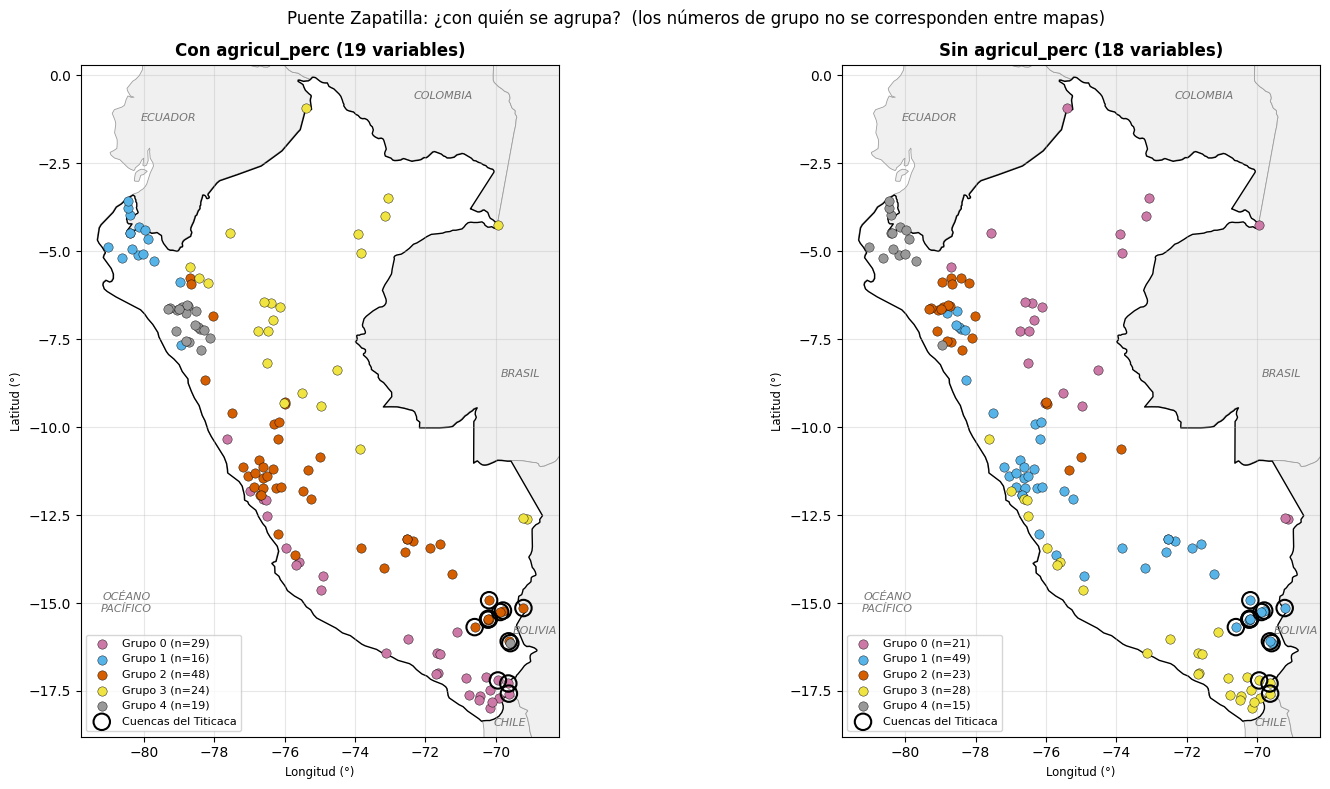

In [25]:
# Repetir PCA + K-Means SIN agricul_perc
X_sin = X_cam.drop(columns=['agricul_perc'])
pca_sin = PCA()
S_sin = pca_sin.fit_transform(StandardScaler().fit_transform(X_sin))[:, :n_cp]
km_sin = KMeans(n_clusters=k_opt, n_init=20, random_state=42)
grupo_sin = km_sin.fit_predict(S_sin)
g_caso_sin = grupo_sin[i_caso]

print(f"Sin agricul_perc: {X_sin.shape[1]} variables, {n_cp} CPs "
      f"({pca_sin.explained_variance_ratio_[:n_cp].sum():.1%} de la varianza), k = {k_opt}")
print(f"Silueta: con agricul_perc = {silhouette_score(S_cp, grupo_cam):.2f} | "
      f"sin agricul_perc = {silhouette_score(S_sin, grupo_sin):.2f}")

print("\nCuencas del Titicaca por grupo:")
print("  con agricul_perc:", camels.loc[es_tit, 'grupo_pca'].value_counts().sort_index().to_dict())
print("  sin agricul_perc:", pd.Series(grupo_sin[es_tit]).value_counts().sort_index().to_dict())
companeras = (grupo_sin == g_caso_sin) & es_tit & (camels.index != i_caso)
print(f"\nAhora Puente Zapatilla está en el grupo {g_caso_sin}, junto con {companeras.sum()} cuencas del Titicaca.")
print(f"Composición de ese grupo:",
      camels.loc[grupo_sin == g_caso_sin, 'gauge_region'].map(nombres_vertiente).value_counts().to_dict())

# Mapas antes / después
fig, ejes = plt.subplots(1, 2, figsize=(16, 8))
for ax, grupos, titulo in [(ejes[0], grupo_cam, 'Con agricul_perc (19 variables)'),
                           (ejes[1], grupo_sin, 'Sin agricul_perc (18 variables)')]:
    agregar_paises(ax)
    for g in range(k_opt):
        m = grupos == g
        ax.scatter(camels.loc[m, 'gauge_lon'], camels.loc[m, 'gauge_lat'], c=colores_grupo[g], s=45,
                   edgecolors='k', linewidths=0.3, zorder=3, label=f'Grupo {g} (n={m.sum()})')
    ax.scatter(camels.loc[es_tit, 'gauge_lon'], camels.loc[es_tit, 'gauge_lat'], s=140, facecolors='none',
               edgecolors='black', linewidths=1.5, zorder=4, label='Cuencas del Titicaca')
    #ax.scatter(camels.loc[i_caso, 'gauge_lon'], camels.loc[i_caso, 'gauge_lat'], s=420, marker='*',
    #           c=colores_grupo[grupos[i_caso]], edgecolors='red', linewidths=1.5, zorder=5, label='Puente Zapatilla')
    ax.set_title(titulo, fontweight='bold'); ax.grid(alpha=0.3)
    ax.set_xlabel('Longitud (°)'); ax.set_ylabel('Latitud (°)')
    ax.legend(loc='lower left', fontsize=8)
plt.suptitle('Puente Zapatilla: ¿con quién se agrupa?  (los números de grupo no se corresponden entre mapas)', #  (estrella)
             fontsize=12)
plt.tight_layout()
plt.show()

**Resultado:** sin `agricul_perc`, Puente Zapatilla **vuelve al grupo de las cuencas del Titicaca** (puna altoandina), junto con
9 de las otras 12 cuencas del Titicaca. La silueta baja un poco: es esperable al quitar una variable
que separaba bien a algunas cuencas.

Fíjate también en las **3 cuencas del Titicaca** que, en ambos análisis, quedan con cuencas del **Pacífico sur**
(Canal Uchusuma, Chuapalca y Ancoaque, ~17° S). No es un error: están en el altiplano **sur**, mucho más **árido** (aridez ~2.5–3.4,
frente a ~1.5 en el resto del Titicaca), y en eso se parecen a las cabeceras áridas del Pacífico sur.

**Lecciones:**

1. **K-Means agrupa por similitud en todas las dimensiones retenidas.** Basta con que una cuenca se aleje mucho en un CP para que cambie de grupo,
   aunque se parezca en todo lo demás.
2. **La selección de variables es una decisión del analista**, guiada por la pregunta. Para regionalizar por **controles naturales**,
   tiene sentido excluir coberturas creadas por el ser humano. Para estudiar el **impacto humano**, habría que incluirlas.
3. **Los grupos de K-Means no son "verdades"**: son una herramienta para explorar. Siempre hay que revisar los casos raros con conocimiento del territorio.

### 9.8 ¿Los componentes explican el caudal?

Las firmas hidrológicas **no** entraron al PCA. Si los CPs (construidos solo con atributos físicos) se relacionan con el caudal,
significa que capturan los controles físicos de la respuesta hidrológica. Esta idea es la base de la regionalización
con modelos de aprendizaje automático, que veremos en el **Lab 8_3 (Random Forest)**.

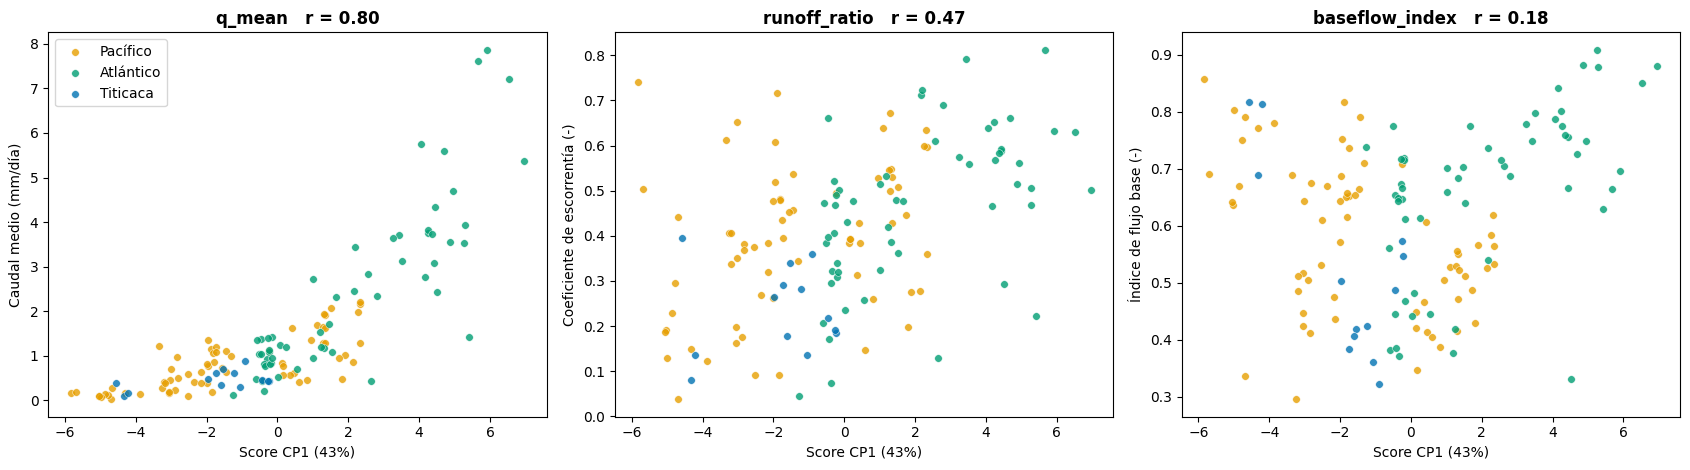

Correlación de los 5 CPs retenidos con las firmas hidrológicas:
     q_mean  runoff_ratio  baseflow_index
CP1    0.80          0.47            0.18
CP2   -0.02         -0.03            0.08
CP3   -0.28         -0.04           -0.60
CP4   -0.22         -0.01           -0.22
CP5   -0.18         -0.04           -0.00


In [26]:
firmas = {'q_mean': 'Caudal medio (mm/día)',
          'runoff_ratio': 'Coeficiente de escorrentía (-)',
          'baseflow_index': 'Índice de flujo base (-)'}
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (var, etiqueta) in zip(ejes, firmas.items()):
    for reg, color in colores_vertiente.items():
        m = (camels['gauge_region'] == reg).values
        ax.scatter(S_cam[m, 0], camels.loc[m, var], c=color, s=30, alpha=0.8,
                   edgecolors='white', linewidths=0.4, label=nombres_vertiente[reg])
    r = np.corrcoef(S_cam[:, 0], camels[var])[0, 1]
    ax.set_xlabel(f'Score CP1 ({ratio[0]:.0%})'); ax.set_ylabel(etiqueta)
    ax.set_title(f'{var}   r = {r:.2f}', fontweight='bold')
ejes[0].legend()
plt.tight_layout()
plt.show()

print(f"Correlación de los {n_cp} CPs retenidos con las firmas hidrológicas:")
print(pd.DataFrame({var: [np.corrcoef(S_cp[:, k], camels[var])[0, 1] for k in range(n_cp)] for var in firmas},
                   index=nombres_cp).round(2))

**Preguntas para discutir**

1. CP1 se relaciona muy bien con `q_mean`. ¿Por qué tiene sentido físico? (Pista: balance hídrico $Q \approx P - ET$.)
2. `baseflow_index` casi no se relaciona con CP1, pero sí con **CP3**. Revisa las cargas de CP3 en el mapa de calor:
   ¿qué tipo de cuenca representa? ¿Tiene sentido que controle el aporte de agua subterránea al río?
3. ¿Los grupos de K-Means coinciden con las vertientes? ¿Qué cuencas "cambian de bando" y por qué podría ser?
4. Repite el análisis **sin** aplicar log a `area` y `aridity`. ¿Cambia la interpretación de CP1?
5. Cambia `n_cp` a 4 y a 8 y vuelve a ejecutar 9.3–9.8. ¿Cambian los grupos de K-Means? ¿Y la silueta?
6. Agrega al PCA alguna de las 17 variables físicas excluidas (por ejemplo `oxisols_perc` o `water_perc`). ¿Aparece un CP nuevo? ¿Qué cuencas lo dominan?

---
## 10. 🔬 Ejercicio: PCA en variables climatológicas andinas

Usando datos climatológicos **sintéticos** de estaciones SENAMHI en la cuenca del Mantaro:

1. Aplica PCA sobre las 5 variables climáticas (¡no olvides estandarizar!).
2. Construye la gráfica de Scree: ¿cuántos componentes necesitas para el 90% de la varianza?
3. Visualiza las estaciones en el espacio CP1–CP2 y coloréalas por altitud.
4. Construye el biplot: ¿qué variables contribuyen más a CP1 y a CP2? ¿Qué variable "va por su cuenta"?

In [27]:
# Dataset sintético de estaciones SENAMHI en la cuenca del Mantaro
np.random.seed(42)
n_estaciones = 150

altitud_est      = np.random.uniform(1500, 4800, n_estaciones)  # msnm
temp_media       = 28 - 0.006 * altitud_est + np.random.normal(0, 1.5, n_estaciones)  # °C
precip_anual     = 800 + 0.15 * altitud_est - 0.00005 * altitud_est**2 + np.random.normal(0, 150, n_estaciones)
humedad_rel      = 60 + 0.005 * altitud_est + np.random.normal(0, 8, n_estaciones)
velocidad_viento = 2 + 0.001 * altitud_est + np.random.normal(0, 1, n_estaciones)
dias_helada      = np.maximum(0, -5 + 0.005 * altitud_est + np.random.normal(0, 10, n_estaciones))

X_mantaro = np.column_stack([
    temp_media, precip_anual, humedad_rel, velocidad_viento, dias_helada
])
nombres_vars_mantaro = ['Temperatura (°C)', 'Precipitación (mm)', 'Humedad (%)',
                        'Viento (m/s)', 'Días helada']

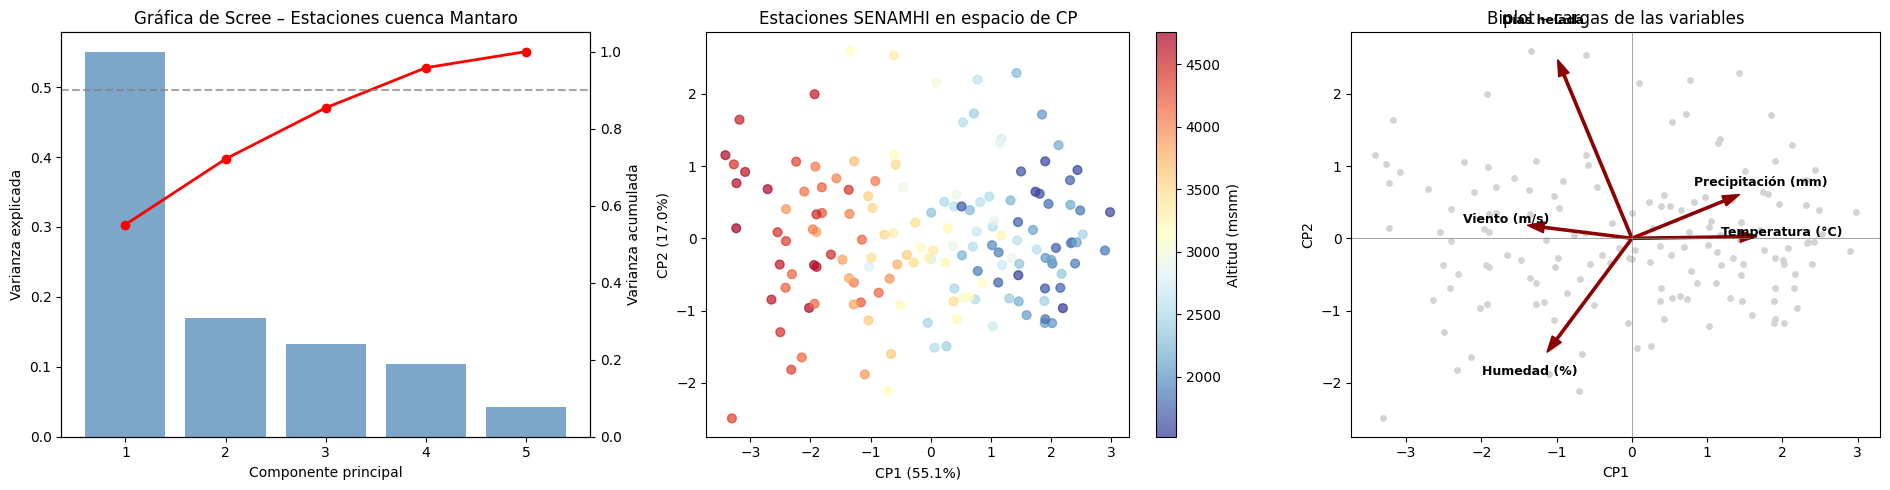

Varianza explicada acumulada:
  1 CP(s): 55.1%
  2 CP(s): 72.1%
  3 CP(s): 85.4%
  4 CP(s): 95.8%
  5 CP(s): 100.0%

→ CPs necesarios para el 90%: 4

Cargas:
                     CP1   CP2
Temperatura (°C)    0.55  0.01
Precipitación (mm)  0.48  0.20
Humedad (%)        -0.38 -0.53
Viento (m/s)       -0.46  0.06
Días helada        -0.33  0.82


In [28]:
# --- Solución ---
esc_mantaro = StandardScaler()
X_mantaro_e = esc_mantaro.fit_transform(X_mantaro)

pca_mantaro = PCA()
X_pca_mantaro = pca_mantaro.fit_transform(X_mantaro_e)
var_acum = np.cumsum(pca_mantaro.explained_variance_ratio_)

fig, ejes = plt.subplots(1, 3, figsize=(19, 5))

# 1–2. Gráfica de Scree + varianza acumulada
ejes[0].bar(range(1, 6), pca_mantaro.explained_variance_ratio_, color='steelblue', alpha=0.7)
ax2 = ejes[0].twinx()
ax2.plot(range(1, 6), var_acum, 'ro-', linewidth=2)
ax2.axhline(0.90, color='gray', linestyle='--', alpha=0.7)
ax2.set_ylabel('Varianza acumulada'); ax2.set_ylim(0, 1.05)
ejes[0].set_xlabel('Componente principal'); ejes[0].set_ylabel('Varianza explicada')
ejes[0].set_title('Gráfica de Scree – Estaciones cuenca Mantaro')

# 3. Dispersión coloreada por altitud
sc = ejes[1].scatter(X_pca_mantaro[:, 0], X_pca_mantaro[:, 1],
                     c=altitud_est, cmap='RdYlBu_r', s=40, alpha=0.7)
plt.colorbar(sc, ax=ejes[1], label='Altitud (msnm)')
ejes[1].set_xlabel(f'CP1 ({pca_mantaro.explained_variance_ratio_[0]:.1%})')
ejes[1].set_ylabel(f'CP2 ({pca_mantaro.explained_variance_ratio_[1]:.1%})')
ejes[1].set_title('Estaciones SENAMHI en espacio de CP')

# 4. Biplot
ejes[2].scatter(X_pca_mantaro[:, 0], X_pca_mantaro[:, 1], c='lightgray', s=15)
cargas_m = pca_mantaro.components_[:2].T
escala = 3
for j, nombre in enumerate(nombres_vars_mantaro):
    ejes[2].arrow(0, 0, cargas_m[j, 0] * escala, cargas_m[j, 1] * escala, color='darkred',
                  width=0.03, head_width=0.15, length_includes_head=True)
    ejes[2].text(cargas_m[j, 0] * escala * 1.2, cargas_m[j, 1] * escala * 1.2, nombre,
                 fontsize=9, fontweight='bold', ha='center')
ejes[2].axhline(0, color='gray', lw=0.5); ejes[2].axvline(0, color='gray', lw=0.5)
ejes[2].set_xlabel('CP1'); ejes[2].set_ylabel('CP2')
ejes[2].set_title('Biplot – cargas de las variables')

plt.tight_layout()
plt.show()

print("Varianza explicada acumulada:")
for i, v in enumerate(var_acum):
    print(f"  {i+1} CP(s): {v:.1%}")
print(f"\n→ CPs necesarios para el 90%: {int(np.argmax(var_acum >= 0.90) + 1)}")
print("\nCargas:")
print(pd.DataFrame(cargas_m, index=nombres_vars_mantaro, columns=['CP1', 'CP2']).round(2))

---
## 11. Errores comunes al usar PCA

**1. Olvidar estandarizar.**
PCA busca la máxima *varianza*. Si una variable tiene un rango mucho mayor (ej. altitud en metros frente a temperatura en °C),
dominará CP1 simplemente por sus unidades, no porque sea más informativa.
**Siempre estandariza antes de aplicar PCA**, salvo que todas las variables ya estén en la misma escala.

**2. Sobreinterpretar componentes pequeños.**
Los últimos CPs explican muy poca varianza y suelen ser ruido. No intentes asignar significado
ecológico a un CP5 que explica el 2% de la varianza.

**3. PCA asume relaciones lineales.**
PCA encuentra combinaciones lineales. Si el patrón principal es no lineal (un gradiente curvo),
necesitará más componentes. Para reducción no lineal existen t-SNE y UMAP (fuera del alcance del curso, pero vale la pena conocerlos).
Lo vemos en la celda siguiente.

**4. Los CPs no siempre son interpretables.**
A veces CP1 es claramente un eje de "tamaño", "verdor" o "humedad". Otras veces las cargas son una mezcla compleja que
no admite una interpretación sencilla. No pasa nada: PCA sigue siendo útil para comprimir aunque sea difícil de interpretar.

**5. Alta varianza no siempre significa alta importancia.**
PCA encuentra direcciones de máxima *varianza*, pero varianza y *relevancia* no son lo mismo. Imagina que en el ejemplo del auto
una variable fuera "número de veces que el dueño anterior cantó en el auto": podría variar muchísimo y ser totalmente irrelevante
para tu decisión. PCA la consideraría importante solo porque varía.

En datos ambientales pasa con variables como códigos de estación, números de sensor, códigos de parcela o fechas codificadas como enteros.
**Aporta siempre conocimiento del dominio a la interpretación.** PCA te dice *qué varía*; tú decides *qué importa*.

**6. Ajustar PCA con todos los datos antes de validar un modelo.**
Si PCA es un paso previo a un clasificador, debe ir **dentro** de un `Pipeline` para que se ajuste solo con datos de entrenamiento (sección 8).

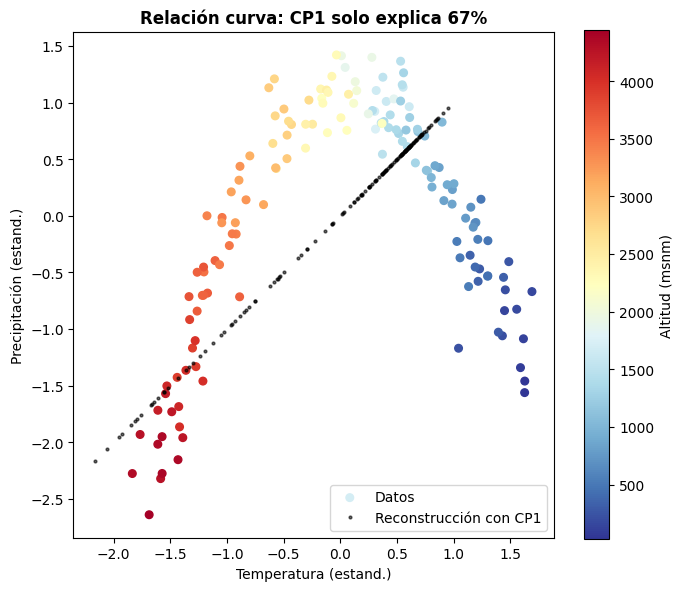

La altitud ordena perfectamente el arco, pero una recta (CP1) no puede seguirlo:
las estaciones bajas y altas quedan proyectadas en el mismo lugar.


In [29]:
# Error 3 en acción: una relación NO lineal
# En los Andes la precipitación suele tener un máximo a altitudes intermedias → forma de arco
np.random.seed(42)
alt = np.random.uniform(0, 4500, 150)
temp_arco = 26 - 0.0065 * alt + np.random.normal(0, 1.0, 150)
prec_arco = 2000 - 0.3 * (alt - 2000)**2 / 1000 + np.random.normal(0, 120, 150)

X_arco = StandardScaler().fit_transform(np.column_stack([temp_arco, prec_arco]))
pca_arco = PCA(n_components=1).fit(X_arco)
X_rec = pca_arco.inverse_transform(pca_arco.transform(X_arco))   # reconstrucción con 1 CP

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(X_arco[:, 0], X_arco[:, 1], c=alt, cmap='RdYlBu_r', s=30, label='Datos')
ax.plot(X_rec[:, 0], X_rec[:, 1], 'k.', ms=4, alpha=0.6, label='Reconstrucción con CP1')
plt.colorbar(sc, label='Altitud (msnm)')
ax.set_aspect('equal')
ax.set_xlabel('Temperatura (estand.)'); ax.set_ylabel('Precipitación (estand.)')
ax.set_title(f'Relación curva: CP1 solo explica {pca_arco.explained_variance_ratio_[0]:.0%}',
             fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()
print("La altitud ordena perfectamente el arco, pero una recta (CP1) no puede seguirlo:")
print("las estaciones bajas y altas quedan proyectadas en el mismo lugar.")

---
## 12. Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Qué hace PCA | Encuentra nuevos ejes (CPs) que capturan la máxima varianza |
| CP1 | Dirección de mayor varianza; CP2 es perpendicular a CP1, etc. |
| Cómo se calcula | Centrar/estandarizar → matriz de covarianza → eigenvectores (direcciones) y eigenvalores (varianza) |
| Varianza = información | Las variables (o direcciones) que más varían son las que más distinguen a las observaciones |
| Gráfica de Scree | Muestra la varianza explicada por cada CP; ayuda a decidir cuántos conservar (80–90%, Kaiser, codo) |
| Biplot | Muestra puntos (scores) y vectores de carga: revela qué variables impulsan cada CP |
| Signo de los CPs | Es arbitrario; interpreta qué variables cargan juntas o en sentido opuesto |
| Estandarizar primero | Siempre; si no, las características con mayor rango dominan |
| Variables asimétricas | Transformar (ej. log10 del área) antes de PCA |
| PCA + K-Means | PCA reduce dimensiones para el clustering y proporciona visualización 2D |
| PCA como preprocesamiento | Dentro de un `Pipeline`; útil para KNN/SVM/NB, menos para métodos basados en árboles |
| Limitaciones | Asume relaciones lineales; los CPs pueden ser difíciles de interpretar; varianza ≠ relevancia |
| Selección de variables | Solo variables numéricas, físicas y no redundantes (19 de 79 en CAMELS-PE); decisión del analista |
| Cuántos CPs | Los criterios (80–90%, Kaiser, codo) pueden no coincidir: decidir y justificar, y usar ese número de forma consistente |
| Cuántos CPs (criterios) | 80–90% de varianza, Kaiser, codo y análisis paralelo: buscar un equilibrio según el uso (interpretar vs. comprimir) |
| Análisis paralelo | Comparar cada eigenvalor con el que produce el **azar** (tablas de ruido del mismo tamaño); conservar solo los que lo superan |
| Revisar casos raros | Una cuenca puede cambiar de grupo por una sola variable (ej. `agricul_perc`): la selección de variables cambia los grupos |
| CAMELS-PE | 5 CPs (~84%) de 19 atributos de 136 cuencas; los 4 primeros (humedad, altitud/energía, agricultura/tamaño, geología) son los más interpretables |

### Resumen de aprendizaje no supervisado

| Lab | Algoritmo | Qué descubre |
|-----|-----------|---------------|
| 8_1 | K-Means | Grupos (clusters) en los datos |
| **8_2** | **PCA** | **Dimensiones (ejes) que capturan la mayor variación** |

**Siguiente:** en el Lab 8_3 usaremos los mismos atributos de CAMELS-PE para **predecir** el caudal con Random Forest.